# Data fusion rule experiment

Compare built-in and custom PyDI fusion rules on the medicine groups in `fusion_eval_worksheet.csv`.

[Experiment report](report.md) · [CSV results](csv/) · [Figures](figures/)

## 1. Experiment setup

**Objective:** identify the most accurate fusion function for each attribute.

Each medicine has values from DPD, EMA and/or FDA. A fusion function combines or selects those values. We compare its output with the reviewed **gold value** in `fusion_eval_worksheet.csv`.

### Attribute selection

The study follows the ten attributes in the reviewed evaluation worksheet.

| Scope | Attributes | Reason |
|---|---|---|
| Evaluated | `brandName`, `activeSubstances`, `activeSubstanceCount`, `licenceHolder`, `productClass`, `atcCode`, `dosageForm`, `route`, `strengths`, `biosimilar` | Reviewed gold values support rule comparison; `activeSubstanceCount` is derived from fused `activeSubstances` |
| Excluded dates | `usApprovalDate`, `euAuthorisationDate`, `caStatusDate` | Each field belongs to one source's jurisdiction, so there is no cross-source conflict for that date |
| Excluded jurisdiction-specific fields | `regulatoryStatus`, `generic`, `orphanMedicine` | Their meanings depend on the jurisdiction; a single gold value requires a jurisdiction policy |

For example, `usApprovalDate` and `euAuthorisationDate` describe different regulatory events. A medicine can also have different `regulatoryStatus` values in Canada and the EU. These exclusions follow the [evaluation-set guide](../../src/data_fusion/role2_eval_set.md). The full pipeline retains these six fields using PyDI's default first-available-value behavior.

### Experiment workflow

| Step | Experiment | Interpretation |
|---|---|---|
| 1. Prepare data | Load every CSV row; lowercase text and normalize whitespace | The source inputs and gold values use consistent formatting |
| 2. Run a baseline | Longest string for text, voting for categories, union for sets | A simple starting score |
| 3. Test each attribute | Try the applicable built-in functions and FDA, EMA and DPD priority orders | Which function works best for each attribute |
| 4. Test custom improvements | Name consensus for `licenceHolder`; unit-normalized union for `strengths` | Whether these change the fused values usefully |
| 5. Evaluate in two ways | Strict accuracy and adaptive accuracy | Exact agreement and agreement under the explained domain comparisons |
| 6. Select rules | Choose the highest adaptive accuracy per attribute | One selected rule and the equally best alternatives |
| 7. Assess the combination | Run the selected attribute rules together | Overall accuracy and density |

### Evaluation measures

| Measure | Meaning | Example |
|---|---|---|
| Strict accuracy | Fraction of gold values matched using the original comparisons | `50 mg/mL` matches `50 mg/mL` |
| Adaptive accuracy | Fraction matched using attribute-specific comparisons for names, units, rounding and broad form families | `0.05 g/mL` matches `50 mg/mL` after conversion |
| Density | Fraction of attribute cells containing a value | 90 populated cells out of 100 gives 90% |
| Input consistency | Fraction of source groups whose available values agree | DPD and FDA both supply `oral` |

**Adaptive accuracy** is this notebook's name for accuracy calculated with the custom comparisons explained in **3.4**. Their settings stay fixed across all tested fusion functions. `activeSubstanceCount` is derived from the fused `activeSubstances` set.

### Notebook structure

- **3. Custom rules:** observed problems, examples and proposed solutions.
- **5. Attribute tests:** each attribute's scores, errors and tied outputs.
- **6. Results:** overall summary, heatmaps and combined metrics.
- **7. Observations and conclusions:** findings and limitations.

Error tables show the two highest adaptive-accuracy levels, including ties. Apply the tie-breaker policy in **6.3**. Selection and assessment use the same sample, so the scores describe development performance.

In [230]:
import logging
from decimal import Decimal
from pathlib import Path

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PyDI.fusion import (
    DataFusionEngine, DataFusionStrategy, DataFusionEvaluator,
    longest_string, shortest_string, most_complete, voting,
    union, intersection, intersection_k_sources, prefer_higher_trust,
    tokenized_match, set_equality_match, exact_match,
)
from PyDI.fusion.engine import build_record_groups_from_correspondences
from PyDI.fusion.base import _is_valid_value

logging.getLogger('PyDI').setLevel(logging.WARNING)
project_root = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
                    if (folder / 'data/8_fusion_eval').is_dir())
work_dir = project_root / 'notebooks/data_fusion_rule_experiment'
csv_dir = work_dir / 'csv'
figure_dir = work_dir / 'figures'
csv_dir.mkdir(exist_ok=True)
figure_dir.mkdir(exist_ok=True)
input_path = project_root / 'data/8_fusion_eval/fusion_eval_worksheet.csv'
attributes = [
    'brandName', 'activeSubstances', 'activeSubstanceCount', 'licenceHolder',
    'productClass', 'atcCode', 'dosageForm', 'route', 'strengths', 'biosimilar',
]
set_attributes = ['activeSubstances', 'atcCode', 'dosageForm', 'route', 'strengths']
text_attributes = ['brandName', 'licenceHolder']
fusion_attributes = [attribute for attribute in attributes if attribute != 'activeSubstanceCount']

## 2. Data preparation
### 2.1 Load evaluation data

Split each `src_*` cell at source boundaries, retaining the source IDs supplied by the worksheet.

- `activeSubstances`, `atcCode`, `dosageForm`, `route`: `list[str]`
- `strengths`: `list[tuple[str, str | None]]` (amount or range, unit)
- `activeSubstanceCount`: `int`
- `biosimilar`: `bool`
- Empty cells: `None`

In [201]:
def load_fusion_eval_set(path):
    """Load and prepare the evaluation set for PyDI fusion-rule experiments."""
    # Load CSV
    worksheet = pd.read_csv(path, sep=';', dtype=str, keep_default_na=False)
    source_rows = {source: [] for source in ['DPD', 'EMA', 'FDA']}
    gold_rows = []
    pair_rows = []

    for row in worksheet.to_dict('records'):
        # Split Source Values
        source_values = {}
        for attribute in attributes:
            source_values[attribute] = dict(
                part.split(': ', 1)
                for part in row['src_' + attribute].split(' | ') if part
            )

        # Build Source Records
        members = []
        records = []
        for source in source_rows:
            record_id = row[source.lower() + '_id']
            if record_id:
                members.append(record_id)
                record = {'id': record_id}
                record.update({
                    attribute: source_values[attribute].get(source, '')
                    for attribute in attributes
                })
                records.append((source, record))

        # Build Gold Record
        gold = {'id': row['eval_id']}
        gold.update({attribute: row['gold_' + attribute] for attribute in attributes})
        records.append(('gold', gold))

        # Convert Types
        for source, record in records:
            for attribute in attributes:
                value = record[attribute].strip()
                if not value:
                    # Empty cell -> None
                    record[attribute] = None
                elif attribute == 'strengths':
                    # strengths -> list of (amount text, unit) pairs
                    strengths = []
                    for item in value.split('; '):
                        parts = item.split(maxsplit=1)
                        # Normalize numeric text and preserve range endpoints.
                        amount = '-'.join(
                            format(Decimal(bound).normalize(), 'f')
                            for bound in parts[0].replace('–', '-').split('-')
                        )
                        strengths.append((amount, ' '.join(parts[1].split()) if len(parts) > 1 else None))
                    record[attribute] = strengths
                elif attribute in set_attributes:
                    # activeSubstances, atcCode, dosageForm, route -> list[str]
                    record[attribute] = sorted({' '.join(item.split()).lower() for item in value.split('; ')})
                elif attribute == 'activeSubstanceCount':
                    # activeSubstanceCount -> int
                    record[attribute] = int(value)
                elif attribute == 'biosimilar':
                    # biosimilar -> bool
                    record[attribute] = value.lower() == 'true'
                else:
                    # brandName, licenceHolder, productClass -> str
                    record[attribute] = ' '.join(value.split()).lower()
            if source == 'gold':
                gold_rows.append(record)
            else:
                source_rows[source].append(record)

        # Link Group Members
        for member in members[1:]:
            pair_rows.append((members[0], member, 1.0))  # Positive link indicator.

    # Build PyDI Inputs
    datasets = {}
    for source, records in source_rows.items():
        frame = pd.DataFrame(records, columns=['id', *attributes], dtype=object)
        frame = frame.drop_duplicates('id').reset_index(drop=True)
        frame.attrs.update(dataset_name=source, trust_score=1.0)
        datasets[source] = frame

    correspondences = pd.DataFrame(pair_rows, columns=['id1', 'id2', 'similarity'])
    gold = pd.DataFrame(gold_rows, columns=['id', *attributes], dtype=object)
    return datasets, correspondences, gold

In [202]:
datasets, correspondences, gold = load_fusion_eval_set(input_path)
gold_ids = set(gold['id'])
tied_outputs = {}
display(pd.DataFrame({'source': list(datasets),
                      'records': [len(frame) for frame in datasets.values()]}))
print(f'{len(gold)} medicines | {len(attributes)} evaluated attributes')
display(gold.head())

,source,records
0,DPD,24
1,EMA,27
2,FDA,23


31 medicines | 10 evaluated attributes


,id,brandName,activeSubstances,activeSubstanceCount,licenceHolder,productClass,atcCode,dosageForm,route,strengths,biosimilar
0,FDA_AGENERASE|AMPRENAVIR,agenerase,[amprenavir],1,glaxosmithkline,human,[j05ae05],"[capsule, solution]",[oral],"[(50, mg), (150, mg), (15, mg/mL)]",False
1,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,bosulif,[bosutinib],1,pf prism c.v.,human,[l01ea04],"[capsule, tablet]",[oral],"[(50, mg), (100, mg), (400, mg), (500, mg)]",False
2,FDA_CINQAIR|RESLIZUMAB,cinqair,[reslizumab],1,"teva respiratory, llc",human,[r03dx08],[injection],[intravenous],"[(10, mg/mL)]",False
3,FDA_ELELYSO|TALIGLUCERASE ALFA,elelyso,[taliglucerase alfa],1,pfizer inc.,human,[a16ab11],[powder for solution],[intravenous],"[(200, U)]",False
4,FDA_HEMLIBRA|EMICIZUMAB,hemlibra,[emicizumab],1,"genentech, inc.",human,[b02bx06],[injection],[subcutaneous],"[(30, mg/mL), (150, mg/mL)]",False


### 2.2 Normalization

- `brandName`, `licenceHolder`, `productClass` and string members of `activeSubstances`, `atcCode`, `dosageForm`, `route`: lowercase, trim and collapse whitespace.
- `strengths`: normalize amount text and unit whitespace; preserve unit case.

### 2.3 Built-in rules

- `brandName`, `licenceHolder`: longest string, shortest string, most complete (non-whitespace characters), voting (equal weights).
- `activeSubstances`, `atcCode`, `dosageForm`, `route`, `strengths`: union, intersection, intersection (`k=2`), whole-set voting (equal weights).
- `productClass`, `biosimilar`: voting (equal weights).
- FDA priority: FDA → EMA → DPD.
- EMA priority: EMA → FDA → DPD.
- DPD priority: DPD → EMA → FDA.
- `activeSubstanceCount`: derive from the fused `activeSubstances` set.

The simple configuration uses longest string for text, voting for categories and union for sets.

## 3. Custom rules
### 3.1 `licenceHolder`

**Observations**

Some sources shorten `licenceHolder` names. The original comparison marks these differences as errors.

| Medicine | Fusion input | Gold value |
|---|---|---|
| Elelyso | `pfizer` | `pfizer inc.` |
| Kanuma | `alexion pharm` | `alexion pharmaceuticals, inc.` |
| Epivir | `viiv hlthcare` | `viiv healthcare company` |

**Proposed improvements**

- **Fusion:** choose the source name most similar, on average, to the other source names. This is the name-consensus rule.
- **Adaptive evaluation:** accept sufficiently similar spellings or matching abbreviated words. Settings: character similarity ≥ 0.85; abbreviation prefixes contain at least three characters.

The fused `licenceHolder` remains a single source name. The adaptive score reports name resemblance.

In [203]:
from difflib import SequenceMatcher
import re

def holder_name_match(actual, expected, threshold=0.85):
    """Compare holder names with automatic character and token similarity."""
    if actual is None or expected is None:
        return actual is None and expected is None

    # Compare Full Names
    first = ' '.join(re.findall(r'\w+', actual.lower()))
    second = ' '.join(re.findall(r'\w+', expected.lower()))
    if SequenceMatcher(None, first, second).ratio() >= threshold:
        return True

    # Compare Abbreviated Tokens
    shorter, longer = sorted([first.split(), second.split()], key=len)
    if not shorter:
        return False
    graph = nx.Graph()
    graph.add_nodes_from([('left', i) for i in range(len(shorter))], bipartite=0)
    for i, token in enumerate(shorter):
        for j, other in enumerate(longer):
            prefix = min(len(token), len(other)) >= 3 and (token.startswith(other) or other.startswith(token))
            if prefix or SequenceMatcher(None, token, other).ratio() >= threshold:
                graph.add_edge(('left', i), ('right', j))
    matching = nx.algorithms.bipartite.maximum_matching(
        graph, top_nodes=[('left', i) for i in range(len(shorter))]
    )
    return all(('left', i) in matching for i in range(len(shorter)))


def holder_consensus(values, **kwargs):
    """Select the source holder name with highest mean character similarity."""
    # Compare Source Names
    scores = [
        sum(SequenceMatcher(None, value, other).ratio() for other in values) / len(values)
        for value in values
    ]
    selected = max(range(len(values)), key=lambda index: scores[index])
    return values[selected], scores[selected], {'rule': 'holder_consensus'}

### 3.2 `strengths`

**Observations**

The same quantity can be written with different units or numbers of decimal places.

| Medicine | Fusion input | Gold value | Explanation |
|---|---|---|---|
| Praxbind | `0.05 g/mL` | `50 mg/mL` | Convert grams to milligrams |
| Wegovy | `2.266667 mg/mL` | `2.27 mg/mL` | The gold value is rounded |
| Mounjaro | `4.166667 mg/mL` | `4.17 mg/mL` | The gold value is rounded |

**Proposed improvements**

- **Fusion:** convert compatible mass units to mg and concentration units to mg/mL, then combine unique pairs. This is unit-normalized union.
- **Adaptive evaluation:** convert units and match every pair to one gold pair, allowing up to 0.5% relative numeric difference.
- Preserve ranges and units such as `U/vial` that carry additional meaning. Amount-to-concentration conversion needs a supplied volume.

In [204]:
from pint import UnitRegistry
from pint.errors import UndefinedUnitError, DimensionalityError

unit_registry = UnitRegistry(non_int_type=Decimal)

def normalize_strengths(strengths):
    """Convert compatible strength units while preserving ranges and dimensions."""
    if strengths is None:
        return None

    # Convert Units
    normalized = []
    for amount, unit in strengths:
        bounds = [Decimal(bound) for bound in amount.split('-')]
        target_unit = unit
        if unit is not None:
            try:
                quantity = unit_registry.Quantity(bounds[0], unit)
                if quantity.dimensionality == unit_registry.mg.dimensionality:
                    target_unit = 'mg'
                elif quantity.dimensionality == (unit_registry.mg / unit_registry.mL).dimensionality:
                    target_unit = 'mg/mL'
                if target_unit in ('mg', 'mg/mL'):
                    bounds = [unit_registry.Quantity(bound, unit).to(target_unit).magnitude for bound in bounds]
            except (UndefinedUnitError, DimensionalityError):
                pass
        amount_text = '-'.join(format(bound.normalize(), 'f') for bound in bounds)
        normalized.append((amount_text, target_unit))
    return sorted(set(normalized), key=lambda pair: (pair[1] or '', pair[0]))


def normalized_strength_union(values, **kwargs):
    """Union strengths after compatible unit conversion."""
    return union([normalize_strengths(value) for value in values])


def strength_match(actual, expected, tolerance=0.005):
    """Compare strength sets with compatible units and one-to-one numeric tolerance."""
    first = normalize_strengths(actual)
    second = normalize_strengths(expected)
    if first is None or second is None:
        return first is None and second is None
    if len(first) != len(second):
        return False

    # Match Amounts Within Equal Units
    graph = nx.Graph()
    left_nodes = [('left', i) for i in range(len(first))]
    graph.add_nodes_from(left_nodes, bipartite=0)
    for i, (amount, unit) in enumerate(first):
        first_bounds = [Decimal(bound) for bound in amount.split('-')]
        for j, (target, target_unit) in enumerate(second):
            second_bounds = [Decimal(bound) for bound in target.split('-')]
            if unit == target_unit and len(first_bounds) == len(second_bounds):
                close = all(
                    abs(value - expected_value) <= Decimal(str(tolerance)) * max(abs(value), abs(expected_value))
                    for value, expected_value in zip(first_bounds, second_bounds)
                )
                if close:
                    graph.add_edge(('left', i), ('right', j))
    matching = nx.algorithms.bipartite.maximum_matching(graph, top_nodes=left_nodes)
    return all(node in matching for node in left_nodes)

### 3.3 `dosageForm`

**Observations**

Sources sometimes describe the same product at different levels of detail.

| Medicine | Fusion input | Gold value | Available `route` |
|---|---|---|---|
| Elelyso | `powder` | `powder for solution` | `intravenous` |
| Kesimpta | `solution` | `injection` | `subcutaneous` |
| Leqembi | `solution` | `concentrate` | `intravenous` |

**Proposed improvements**

Keep the fused `dosageForm` values and add an adaptive comparison:

- Group `powder` and `powder for solution` as powder.
- Group `solution`, `injection` and `concentrate` as injectable liquid when every available `route` indicates injection or infusion, such as `intravenous` or `subcutaneous`.

For example, `solution` and `injection` can match with a `subcutaneous` route. An `oral` route keeps those forms distinct.

This score measures agreement at the broad form-family level. Exact preparation and dilution details require product information. Missing and extra distinct forms contribute to errors. [FDA dosage-form terminology](https://www.fda.gov/industry/structured-product-labeling-resources/dosage-forms).

In [205]:
def dosage_form_match(actual, expected):
    """Compare broad form families using the source routes as context."""
    forms, routes = actual
    if forms is None or expected is None:
        return forms is None and expected is None

    # Check Route Context
    parenteral_routes = {'intravenous', 'intramuscular', 'subcutaneous', 'intradermal', 'intrathecal', 'injection'}
    injectable = bool(routes) and set(routes).issubset(parenteral_routes)

    # Compare Form Families
    normalized = []
    for values in [forms, expected]:
        families = set()
        for value in values:
            if value in {'powder', 'powder for solution'}:
                families.add('powder')
            elif injectable and value in {'solution', 'injection', 'concentrate'}:
                families.add('injectable liquid')
            else:
                families.add(value)
        normalized.append(families)
    return normalized[0] == normalized[1]

### 3.4 Adaptive accuracy

Adaptive accuracy uses a comparison suited to each attribute. It applies the following settings to every fusion function.

| Attribute | When a fused value counts as a match |
|---|---|
| `licenceHolder` | The character similarity reaches 0.85, or every token in the shorter name matches a word or abbreviation in the longer name |
| `strengths` | Each amount–unit pair has one corresponding gold pair after compatible unit conversion, with at most 0.5% relative numeric difference |
| `dosageForm` | The form sets agree after the family comparison in 3.3; injectable-liquid grouping requires all available `route` values to be parenteral |
| Other attributes | Use the original comparisons |

**Worked example**

| Attribute | Fused value | Gold value | Strict match | Adaptive match | Reason |
|---|---|---|---|---|---|
| `licenceHolder` | `pfizer` | `pfizer inc.` | No | Yes | The shorter name matches a token in the longer name |
| `strengths` | `0.05 g/mL` | `50 mg/mL` | No | Yes | Both express the same concentration |
| `dosageForm` | `solution` | `injection` | No | Yes | Both fall in the injectable-liquid family when `route=subcutaneous` |
| `strengths` | `50 mg` | `50 mg/mL` | No | No | Converting an amount to a concentration requires volume information |

For these four illustrative values, strict accuracy is **0/4 = 0%** and adaptive accuracy is **3/4 = 75%**.

$$
\mathrm{AdaptiveAccuracy} = \frac{\text{values accepted by the attribute-specific comparisons}}{\text{gold values}}
$$

The fused values in this example stay unchanged. The score increases because the comparison recognizes name resemblance, compatible units and broad form agreement. For `licenceHolder`, this measures name resemblance; confirming the legal company requires separate evidence. For `dosageForm`, this measures broad compatibility; exact preparation details require product information.

In [206]:
# Check Representation Equivalence
assert strength_match([('0.05', 'g/mL')], [('50', 'mg/mL')])
assert strength_match([('2.266667', 'mg/mL')], [('2.27', 'mg/mL')])
assert not strength_match([('50', 'mg')], [('50', 'mg/mL')])
assert not strength_match([('1-2', 'mg')], [('1.5', 'mg')])
assert not strength_match([('1', 'mg'), ('2', 'mg')], [('1', 'mg')])
assert dosage_form_match((['solution'], ['subcutaneous']), ['injection'])
assert not dosage_form_match((['solution'], ['oral']), ['injection'])
assert not dosage_form_match((['injection'], ['intravenous']), ['powder for solution'])
assert not dosage_form_match((None, ['oral']), ['tablet'])
assert holder_name_match('pfizer', 'pfizer inc.')
print('Custom rule checks passed.')

Custom rule checks passed.


## 4. Experiment configuration

Register the built-in and custom rules, then use the shared runner for each attribute.

In [207]:
rule_catalog = {
    'Longest': (longest_string, {}),
    'Shortest': (shortest_string, {}),
    'Most complete': (most_complete, {}),
    'Voting': (voting, {}),
    'Name consensus': (holder_consensus, {}),
    'Unit-normalized union': (normalized_strength_union, {}),
    'Union': (union, {}),
    'Intersection': (intersection, {}),
    'Intersection k=2': (intersection_k_sources, {'k': 2}),
}
for label, order in [
    ('FDA priority', ['FDA', 'EMA', 'DPD']),
    ('EMA priority', ['EMA', 'FDA', 'DPD']),
    ('DPD priority', ['DPD', 'EMA', 'FDA']),
]:
    rule_catalog[label] = (
        prefer_higher_trust,
        {'trust_map': {source: float(3 - rank) for rank, source in enumerate(order)}},
    )

priority_options = ['FDA priority', 'EMA priority', 'DPD priority']
text_options = ['Longest', 'Shortest', 'Most complete', 'Voting', *priority_options]
set_options = ['Union', 'Intersection', 'Intersection k=2', 'Voting', *priority_options]
category_options = ['Voting', *priority_options]

simple_rules = {
    attribute: 'Union' if attribute in set_attributes
    else 'Longest' if attribute in text_attributes else 'Voting'
    for attribute in fusion_attributes
}
comparison_rules = {
    attribute: set_equality_match if attribute in set_attributes
    else tokenized_match if attribute in text_attributes else exact_match
    for attribute in attributes
}
attribute_results = {}
attribute_outputs = {}
wrong_outputs = {}

domain_comparisons = {
    **comparison_rules, 'licenceHolder': holder_name_match,
    'strengths': strength_match, 'dosageForm': dosage_form_match,
}

In [208]:
def run_fusion(rule_choices):
    """Fuse the sample and measure strict and adaptive accuracy."""
    # Define Fusion Strategy
    strategy = DataFusionStrategy('Attribute rules')
    for attribute, label in rule_choices.items():
        resolver, options = rule_catalog[label]
        if attribute in set_attributes and label == 'Voting':
            strategy.add_attribute_fuser(
                attribute, resolver,
                accessor=lambda row, field=attribute: tuple(sorted(row[field])) if row[field] is not None else None,
                **options,
            )
        else:
            strategy.add_attribute_fuser(attribute, resolver, **options)
        strategy.add_evaluation_function(attribute, comparison_rules[attribute])
    strategy.add_evaluation_function('activeSubstanceCount', exact_match)

    # Fuse and Derive Counts
    fused = DataFusionEngine(strategy).run(
        [frame.drop(columns='activeSubstanceCount') for frame in datasets.values()],
        correspondences, id_column='id', include_singletons=True,
    )
    fused['eval_id'] = fused['_fusion_sources'].apply(
        lambda members: next(member for member in members if member in gold_ids)
    )
    fused['activeSubstanceCount'] = fused['activeSubstances'].apply(
        lambda ingredients: len(set(ingredients)) if ingredients is not None else None
    )
    source_routes = {
        row['id']: row['route'] or []
        for frame in datasets.values() for row in frame.to_dict('records')
    }
    fused['_eval_routes'] = fused['_fusion_sources'].apply(
        lambda members: sorted({route for member in members for route in source_routes[member]})
    )

    # Score Strict Accuracy
    strict = DataFusionEvaluator(strategy).evaluate(
        fused_df=fused[['eval_id', *attributes]], fused_id_column='eval_id',
        expected_df=gold, expected_id_column='id',
    )

    # Score Adaptive Accuracy
    adaptive_strategy = DataFusionStrategy('Adaptive comparisons')
    for attribute in attributes:
        adaptive_strategy.add_evaluation_function(attribute, domain_comparisons[attribute])
    comparison_frame = fused[['eval_id', *attributes]].copy()
    comparison_frame['dosageForm'] = list(zip(fused['dosageForm'], fused['_eval_routes']))
    metrics = DataFusionEvaluator(adaptive_strategy).evaluate(
        fused_df=comparison_frame, fused_id_column='eval_id',
        expected_df=gold, expected_id_column='id',
    )
    metrics['strict_overall_accuracy'] = strict['overall_accuracy']
    for attribute in attributes:
        metrics['strict_' + attribute + '_accuracy'] = strict[attribute + '_accuracy']
    return fused, metrics


def test_attribute(attribute, options):
    """Compare attribute rules and collect incorrect values and ties."""
    score_rows, errors, tie_rows = [], [], []
    outputs = {}
    expected = gold.set_index('id')

    for label in options:
        # Test One Attribute
        fused, metrics = run_fusion({**simple_rules, attribute: label})
        outputs[label] = fused
        score_rows.append({
            'rule': label, 'accuracy': metrics[attribute + '_accuracy'],
            'strict_accuracy': metrics['strict_' + attribute + '_accuracy'],
            'density': fused[attribute].map(_is_valid_value).mean(),
            'derived_count_accuracy': metrics['activeSubstanceCount_accuracy'],
        })

        # Collect Adaptive-Score Errors
        for row in fused.to_dict('records'):
            actual = row[attribute]
            target = expected.at[row['eval_id'], attribute]
            compared = (actual, row['_eval_routes']) if attribute == 'dosageForm' else actual
            if not domain_comparisons[attribute](compared, target):
                errors.append({
                    'attribute': attribute, 'rule': label, 'eval_id': row['eval_id'],
                    'fusion_inputs': {
                        source: frame.loc[frame['id'].isin(row['_fusion_sources']), attribute].tolist()
                        for source, frame in datasets.items()
                    },
                    'fused_value': actual, 'gold_value': target,
                })

    scores = pd.DataFrame(score_rows).set_index('rule')
    columns = ['attribute', 'rule', 'eval_id', 'fusion_inputs', 'fused_value', 'gold_value']
    incorrect = pd.DataFrame(errors, columns=columns)
    top_rules = scores.index[scores['accuracy'].rank(method='dense', ascending=False) <= 2]
    incorrect = incorrect.loc[incorrect['rule'].isin(top_rules)].reset_index(drop=True)

    # Collect Tied Best Outputs
    best = scores.loc[scores['accuracy'] == scores['accuracy'].max()]
    if len(best) > 1:
        for label in best.index:
            for row in outputs[label].to_dict('records'):
                tie_rows.append({
                    'attribute': attribute, 'rule': label, 'eval_id': row['eval_id'],
                    'fusion_inputs': {
                        source: frame.loc[frame['id'].isin(row['_fusion_sources']), attribute].tolist()
                        for source, frame in datasets.items()
                    },
                    'fused_value': row[attribute],
                    'gold_value': expected.at[row['eval_id'], attribute],
                })
    tied_outputs[attribute] = pd.DataFrame(tie_rows, columns=columns)
    # Show This Attribute's Results
    display(scores[['strict_accuracy', 'accuracy', 'density']].rename(
        columns={'accuracy': 'adaptive_accuracy'}
    ).round(4))
    print('Incorrect outputs: top two adaptive-accuracy levels')
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
        display(incorrect)
    print('Best rules, including ties')
    display(best[['strict_accuracy', 'accuracy']].rename(columns={'accuracy': 'adaptive_accuracy'}))
    if len(tied_outputs[attribute]):
        print('Values produced by tied best rules')
        with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
            display(tied_outputs[attribute])
    return scores, outputs, incorrect

### 4.1 Simple configuration

Run longest string for `brandName` and `licenceHolder`, voting for `productClass` and `biosimilar`, and union for set-valued attributes. Derive `activeSubstanceCount` from the fused `activeSubstances` set.

In [209]:
simple_fused, simple_metrics = run_fusion(simple_rules)
display(pd.DataFrame({
    'strict_accuracy': {attribute: simple_metrics['strict_' + attribute + '_accuracy'] for attribute in attributes},
    'adaptive_accuracy': {attribute: simple_metrics[attribute + '_accuracy'] for attribute in attributes},
}).round(4))

,strict_accuracy,adaptive_accuracy
brandName,0.9355,0.9355
activeSubstances,0.7097,0.7097
activeSubstanceCount,0.8387,0.8387
licenceHolder,0.0968,0.1935
productClass,1.0000,1.0000
atcCode,0.8065,0.8065
dosageForm,0.4839,0.8387
route,0.8065,0.8065
strengths,0.4516,0.4516
biosimilar,1.0000,1.0000


## 5. Attribute tests
### 5.1 `brandName`

Compare text functions and dataset priorities.

In [210]:
attribute_results['brandName'], attribute_outputs['brandName'], wrong_outputs['brandName'] = test_attribute(
    'brandName', text_options,
)

,strict_accuracy,adaptive_accuracy,density
rule,,,
Longest,0.9355,0.9355,1.0
Shortest,1.0000,1.0000,1.0
Most complete,0.9355,0.9355,1.0
Voting,0.9677,0.9677,1.0
FDA priority,1.0000,1.0000,1.0
EMA priority,0.9677,0.9677,1.0
DPD priority,0.9677,0.9677,1.0


Incorrect outputs: top two adaptive-accuracy levels


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,brandName,Voting,EMA_PREHEVBRI|HEPATITIS B SURFACE ANTIGEN,"{'DPD': ['prehevbrio'], 'EMA': ['prehevbri'], 'FDA': []}",prehevbrio,prehevbri
1,brandName,EMA priority,FDA_CINQAIR|RESLIZUMAB,"{'DPD': ['cinqair'], 'EMA': ['cinqaero'], 'FDA': ['cinqair']}",cinqaero,cinqair
2,brandName,DPD priority,EMA_PREHEVBRI|HEPATITIS B SURFACE ANTIGEN,"{'DPD': ['prehevbrio'], 'EMA': ['prehevbri'], 'FDA': []}",prehevbrio,prehevbri


Best rules, including ties


,strict_accuracy,adaptive_accuracy
rule,,
Shortest,1.0,1.0
FDA priority,1.0,1.0


Values produced by tied best rules


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,brandName,Shortest,FDA_AGENERASE|AMPRENAVIR,"{'DPD': ['agenerase'], 'EMA': ['agenerase'], 'FDA': ['agenerase']}",agenerase,agenerase
1,brandName,Shortest,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': ['bosulif'], 'EMA': ['bosulif'], 'FDA': ['bosulif']}",bosulif,bosulif
2,brandName,Shortest,FDA_CINQAIR|RESLIZUMAB,"{'DPD': ['cinqair'], 'EMA': ['cinqaero'], 'FDA': ['cinqair']}",cinqair,cinqair
3,brandName,Shortest,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': ['elelyso'], 'EMA': ['elelyso'], 'FDA': ['elelyso']}",elelyso,elelyso
4,brandName,Shortest,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': ['hemlibra'], 'EMA': ['hemlibra'], 'FDA': ['hemlibra']}",hemlibra,hemlibra
5,brandName,Shortest,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': ['invanz'], 'EMA': ['invanz'], 'FDA': ['invanz']}",invanz,invanz
6,brandName,Shortest,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': ['kanuma'], 'EMA': ['kanuma'], 'FDA': ['kanuma']}",kanuma,kanuma
7,brandName,Shortest,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': ['kesimpta'], 'EMA': ['kesimpta'], 'FDA': ['kesimpta']}",kesimpta,kesimpta
8,brandName,Shortest,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': ['praxbind'], 'EMA': ['praxbind'], 'FDA': ['praxbind']}",praxbind,praxbind
9,brandName,Shortest,FDA_QUVIVIQ|DARIDOREXANT HYDROCHLORIDE,"{'DPD': ['quviviq'], 'EMA': ['quviviq'], 'FDA': ['quviviq']}",quviviq,quviviq


### 5.2 `activeSubstances`

Compare set functions and dataset priorities; derive ingredient counts from the result.

In [211]:
attribute_results['activeSubstances'], attribute_outputs['activeSubstances'], wrong_outputs['activeSubstances'] = test_attribute(
    'activeSubstances', set_options,
)

,strict_accuracy,adaptive_accuracy,density
rule,,,
Union,0.7097,0.7097,1.0000
Intersection,0.7097,0.7097,0.8387
Intersection k=2,0.7097,0.7097,0.9032
Voting,0.8065,0.8065,1.0000
FDA priority,0.7097,0.7097,1.0000
EMA priority,0.7097,0.7097,1.0000
DPD priority,0.8710,0.8710,1.0000


Incorrect outputs: top two adaptive-accuracy levels


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,activeSubstances,Voting,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': [['ertapenem']], 'EMA': [['ertapenem sodium']], 'FDA': [['ertapenem sodium']]}","(ertapenem sodium,)",[ertapenem]
1,activeSubstances,Voting,FDA_QUVIVIQ|DARIDOREXANT HYDROCHLORIDE,"{'DPD': [['daridorexant']], 'EMA': [['daridorexant hydrochloride']], 'FDA': [['daridorexant hydr...","(daridorexant hydrochloride,)",[daridorexant]
2,activeSubstances,Voting,FDA_FINTEPLA|FENFLURAMINE HYDROCHLORIDE,"{'DPD': [], 'EMA': [['fenfluramine hydrochloride']], 'FDA': [['fenfluramine hydrochloride']]}","(fenfluramine hydrochloride,)",[fenfluramine]
3,activeSubstances,Voting,FDA_IONSYS|FENTANYL HYDROCHLORIDE,"{'DPD': [], 'EMA': [['fentanyl hydrochloride']], 'FDA': [['fentanyl hydrochloride']]}","(fentanyl hydrochloride,)",[fentanyl]
4,activeSubstances,Voting,FDA_MIPLYFFA|ARIMOCLOMOL CITRATE,"{'DPD': [], 'EMA': [['arimoclomol citrate']], 'FDA': [['arimoclomol citrate']]}","(arimoclomol citrate,)",[arimoclomol]
5,activeSubstances,Voting,FDA_MYCAPSSA|OCTREOTIDE ACETATE,"{'DPD': [], 'EMA': [['octreotide acetate']], 'FDA': [['octreotide acetate']]}","(octreotide acetate,)",[octreotide]
6,activeSubstances,DPD priority,FDA_FINTEPLA|FENFLURAMINE HYDROCHLORIDE,"{'DPD': [], 'EMA': [['fenfluramine hydrochloride']], 'FDA': [['fenfluramine hydrochloride']]}",[fenfluramine hydrochloride],[fenfluramine]
7,activeSubstances,DPD priority,FDA_IONSYS|FENTANYL HYDROCHLORIDE,"{'DPD': [], 'EMA': [['fentanyl hydrochloride']], 'FDA': [['fentanyl hydrochloride']]}",[fentanyl hydrochloride],[fentanyl]
8,activeSubstances,DPD priority,FDA_MIPLYFFA|ARIMOCLOMOL CITRATE,"{'DPD': [], 'EMA': [['arimoclomol citrate']], 'FDA': [['arimoclomol citrate']]}",[arimoclomol citrate],[arimoclomol]
9,activeSubstances,DPD priority,FDA_MYCAPSSA|OCTREOTIDE ACETATE,"{'DPD': [], 'EMA': [['octreotide acetate']], 'FDA': [['octreotide acetate']]}",[octreotide acetate],[octreotide]


Best rules, including ties


,strict_accuracy,adaptive_accuracy
rule,,
DPD priority,0.870968,0.870968


### 5.3 `licenceHolder`

Compare text functions, dataset priorities and name-consensus fusion. Measure strict and compatible name accuracy.

In [212]:
attribute_results['licenceHolder'], attribute_outputs['licenceHolder'], wrong_outputs['licenceHolder'] = test_attribute(
    'licenceHolder', [*text_options, 'Name consensus'],
)

,strict_accuracy,adaptive_accuracy,density
rule,,,
Longest,0.0968,0.1935,1.0
Shortest,0.3871,0.8387,1.0
Most complete,0.0968,0.1935,1.0
Voting,0.0323,0.1290,1.0
FDA priority,0.4516,0.9355,1.0
EMA priority,0.2581,0.4194,1.0
DPD priority,0.0323,0.1290,1.0
Name consensus,0.1290,0.2258,1.0


Incorrect outputs: top two adaptive-accuracy levels


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,licenceHolder,Shortest,FDA_CINQAIR|RESLIZUMAB,"{'DPD': ['teva canada limited'], 'EMA': ['teva b.v.'], 'FDA': ['teva respiratory llc']}",teva b.v.,"teva respiratory, llc"
1,licenceHolder,Shortest,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': ['merck canada inc'], 'EMA': ['merck sharp & dohme b.v.'], 'FDA': ['msd sub merck']}",msd sub merck,merck sharp & dohme llc
2,licenceHolder,Shortest,FDA_SEPTRA|SULFAMETHOXAZOLE; TRIMETHOPRIM,"{'DPD': ['glaxosmithkline inc'], 'EMA': [], 'FDA': ['monarch pharms']}",monarch pharms,monarch pharmaceuticals
3,licenceHolder,Shortest,EMA_RASILEZ|ALISKIREN,"{'DPD': ['noden pharma dac'], 'EMA': ['lxo ireland designated activity company'], 'FDA': []}",noden pharma dac,lxo ireland designated activity company
4,licenceHolder,Shortest,FDA_MIPLYFFA|ARIMOCLOMOL CITRATE,"{'DPD': [], 'EMA': ['orphazyme a/s'], 'FDA': ['zevra denmark']}",orphazyme a/s,zevra denmark a/s
5,licenceHolder,FDA priority,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': ['merck canada inc'], 'EMA': ['merck sharp & dohme b.v.'], 'FDA': ['msd sub merck']}",msd sub merck,merck sharp & dohme llc
6,licenceHolder,FDA priority,FDA_SEPTRA|SULFAMETHOXAZOLE; TRIMETHOPRIM,"{'DPD': ['glaxosmithkline inc'], 'EMA': [], 'FDA': ['monarch pharms']}",monarch pharms,monarch pharmaceuticals


Best rules, including ties


,strict_accuracy,adaptive_accuracy
rule,,
FDA priority,0.451613,0.935484


### 5.4 `productClass`

Compare voting and dataset priorities.

In [213]:
attribute_results['productClass'], attribute_outputs['productClass'], wrong_outputs['productClass'] = test_attribute(
    'productClass', category_options,
)

,strict_accuracy,adaptive_accuracy,density
rule,,,
Voting,1.0,1.0,1.0
FDA priority,1.0,1.0,1.0
EMA priority,1.0,1.0,1.0
DPD priority,1.0,1.0,1.0


Incorrect outputs: top two adaptive-accuracy levels


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value


Best rules, including ties


,strict_accuracy,adaptive_accuracy
rule,,
Voting,1.0,1.0
FDA priority,1.0,1.0
EMA priority,1.0,1.0
DPD priority,1.0,1.0


Values produced by tied best rules


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,productClass,Voting,FDA_AGENERASE|AMPRENAVIR,"{'DPD': ['human'], 'EMA': ['human'], 'FDA': ['human']}",human,human
1,productClass,Voting,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': ['human'], 'EMA': ['human'], 'FDA': ['human']}",human,human
2,productClass,Voting,FDA_CINQAIR|RESLIZUMAB,"{'DPD': ['human'], 'EMA': ['human'], 'FDA': ['human']}",human,human
3,productClass,Voting,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': ['human'], 'EMA': ['human'], 'FDA': ['human']}",human,human
4,productClass,Voting,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': ['human'], 'EMA': ['human'], 'FDA': ['human']}",human,human
5,productClass,Voting,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': ['human'], 'EMA': ['human'], 'FDA': ['human']}",human,human
6,productClass,Voting,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': ['human'], 'EMA': ['human'], 'FDA': ['human']}",human,human
7,productClass,Voting,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': ['human'], 'EMA': ['human'], 'FDA': ['human']}",human,human
8,productClass,Voting,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': ['human'], 'EMA': ['human'], 'FDA': ['human']}",human,human
9,productClass,Voting,FDA_QUVIVIQ|DARIDOREXANT HYDROCHLORIDE,"{'DPD': ['human'], 'EMA': ['human'], 'FDA': ['human']}",human,human


### 5.5 `atcCode`

Compare set functions and dataset priorities.

In [214]:
attribute_results['atcCode'], attribute_outputs['atcCode'], wrong_outputs['atcCode'] = test_attribute(
    'atcCode', set_options,
)

,strict_accuracy,adaptive_accuracy,density
rule,,,
Union,0.8065,0.8065,1.0000
Intersection,0.8065,0.8065,0.9032
Intersection k=2,0.8065,0.8065,0.9032
Voting,0.9032,0.9032,1.0000
FDA priority,0.8065,0.8065,1.0000
EMA priority,0.8065,0.8065,1.0000
DPD priority,0.9032,0.9032,1.0000


Incorrect outputs: top two adaptive-accuracy levels


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,atcCode,Union,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': [['a16ab14']], 'EMA': [['a16']], 'FDA': [None]}","[a16, a16ab14]",[a16ab14]
1,atcCode,Union,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': [['l04ag12']], 'EMA': [['l04aa52']], 'FDA': [None]}","[l04aa52, l04ag12]",[l04ag12]
2,atcCode,Union,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': [['v03ab37']], 'EMA': [['v03ab']], 'FDA': [None]}","[v03ab, v03ab37]",[v03ab37]
3,atcCode,Union,FDA_DUREZOL|DIFLUPREDNATE,"{'DPD': [['s01ba']], 'EMA': [], 'FDA': [None]}",[s01ba],[s01ba16]
4,atcCode,Union,FDA_FINTEPLA|FENFLURAMINE HYDROCHLORIDE,"{'DPD': [], 'EMA': [['n03']], 'FDA': [None]}",[n03],[n03ax26]
5,atcCode,Union,FDA_MIPLYFFA|ARIMOCLOMOL CITRATE,"{'DPD': [], 'EMA': [['n07']], 'FDA': [None]}",[n07],[n07xx17]
6,atcCode,Intersection,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': [['a16ab14']], 'EMA': [['a16']], 'FDA': [None]}",[],[a16ab14]
7,atcCode,Intersection,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': [['l04ag12']], 'EMA': [['l04aa52']], 'FDA': [None]}",[],[l04ag12]
8,atcCode,Intersection,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': [['v03ab37']], 'EMA': [['v03ab']], 'FDA': [None]}",[],[v03ab37]
9,atcCode,Intersection,FDA_DUREZOL|DIFLUPREDNATE,"{'DPD': [['s01ba']], 'EMA': [], 'FDA': [None]}",[s01ba],[s01ba16]


Best rules, including ties


,strict_accuracy,adaptive_accuracy
rule,,
Voting,0.903226,0.903226
DPD priority,0.903226,0.903226


Values produced by tied best rules


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,atcCode,Voting,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [['j05ae05']], 'EMA': [['j05ae05']], 'FDA': [None]}","(j05ae05,)",[j05ae05]
1,atcCode,Voting,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [['l01ea04']], 'EMA': [['l01ea04']], 'FDA': [None]}","(l01ea04,)",[l01ea04]
2,atcCode,Voting,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [['r03dx08']], 'EMA': [['r03dx08']], 'FDA': [None]}","(r03dx08,)",[r03dx08]
3,atcCode,Voting,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [['a16ab11']], 'EMA': [['a16ab11']], 'FDA': [None]}","(a16ab11,)",[a16ab11]
4,atcCode,Voting,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [['b02bx06']], 'EMA': [['b02bx06']], 'FDA': [None]}","(b02bx06,)",[b02bx06]
5,atcCode,Voting,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': [['j01dh03']], 'EMA': [['j01dh03']], 'FDA': [None]}","(j01dh03,)",[j01dh03]
6,atcCode,Voting,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': [['a16ab14']], 'EMA': [['a16']], 'FDA': [None]}","(a16ab14,)",[a16ab14]
7,atcCode,Voting,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': [['l04ag12']], 'EMA': [['l04aa52']], 'FDA': [None]}","(l04ag12,)",[l04ag12]
8,atcCode,Voting,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': [['v03ab37']], 'EMA': [['v03ab']], 'FDA': [None]}","(v03ab37,)",[v03ab37]
9,atcCode,Voting,FDA_QUVIVIQ|DARIDOREXANT HYDROCHLORIDE,"{'DPD': [['n05cj03']], 'EMA': [['n05cj03']], 'FDA': [None]}","(n05cj03,)",[n05cj03]


### 5.6 `dosageForm`

Compare set functions and dataset priorities. Measure strict and route-aware form compatibility.

In [215]:
attribute_results['dosageForm'], attribute_outputs['dosageForm'], wrong_outputs['dosageForm'] = test_attribute(
    'dosageForm', set_options,
)

,strict_accuracy,adaptive_accuracy,density
rule,,,
Union,0.4839,0.8387,0.9677
Intersection,0.4516,0.6129,0.7419
Intersection k=2,0.4516,0.6129,0.7419
Voting,0.5161,0.8387,0.9677
FDA priority,0.6774,0.8710,0.9677
EMA priority,0.6774,0.8710,0.9677
DPD priority,0.5161,0.8387,0.9677


Incorrect outputs: top two adaptive-accuracy levels


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,dosageForm,Union,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [['capsule', 'liquid']], 'EMA': [None], 'FDA': [['capsule', 'solution']]}","[capsule, liquid, solution]","[capsule, solution]"
1,dosageForm,Union,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': [['powder for solution']], 'EMA': [None], 'FDA': [['injection']]}","[injection, powder for solution]",[powder for solution]
2,dosageForm,Union,FDA_WEGOVY|SEMAGLUTIDE,"{'DPD': [['solution']], 'EMA': [None], 'FDA': [['solution', 'tablet']]}","[solution, tablet]","[injection, tablet]"
3,dosageForm,Union,FDA_SEPTRA|SULFAMETHOXAZOLE; TRIMETHOPRIM,"{'DPD': [['tablet']], 'EMA': [], 'FDA': [None]}",[tablet],"[injection, suspension, tablet]"
4,dosageForm,Union,FDA_VIJOICE|ALPELISIB,"{'DPD': [], 'EMA': [None], 'FDA': [None]}",None,"[granules, tablet]"
5,dosageForm,Voting,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [['capsule', 'liquid']], 'EMA': [None], 'FDA': [['capsule', 'solution']]}","(capsule, liquid)","[capsule, solution]"
6,dosageForm,Voting,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [['tablet']], 'EMA': [None], 'FDA': [['capsule', 'tablet']]}","(tablet,)","[capsule, tablet]"
7,dosageForm,Voting,FDA_WEGOVY|SEMAGLUTIDE,"{'DPD': [['solution']], 'EMA': [None], 'FDA': [['solution', 'tablet']]}","(solution,)","[injection, tablet]"
8,dosageForm,Voting,FDA_SEPTRA|SULFAMETHOXAZOLE; TRIMETHOPRIM,"{'DPD': [['tablet']], 'EMA': [], 'FDA': [None]}","(tablet,)","[injection, suspension, tablet]"
9,dosageForm,Voting,FDA_VIJOICE|ALPELISIB,"{'DPD': [], 'EMA': [None], 'FDA': [None]}",None,"[granules, tablet]"


Best rules, including ties


,strict_accuracy,adaptive_accuracy
rule,,
FDA priority,0.677419,0.870968
EMA priority,0.677419,0.870968


Values produced by tied best rules


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,dosageForm,FDA priority,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [['capsule', 'liquid']], 'EMA': [None], 'FDA': [['capsule', 'solution']]}","[capsule, solution]","[capsule, solution]"
1,dosageForm,FDA priority,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [['tablet']], 'EMA': [None], 'FDA': [['capsule', 'tablet']]}","[capsule, tablet]","[capsule, tablet]"
2,dosageForm,FDA priority,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [['solution']], 'EMA': [None], 'FDA': [['injection']]}",[injection],[injection]
3,dosageForm,FDA priority,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [['powder for solution']], 'EMA': [None], 'FDA': [['powder']]}",[powder],[powder for solution]
4,dosageForm,FDA priority,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [['solution']], 'EMA': [None], 'FDA': [['injection']]}",[injection],[injection]
5,dosageForm,FDA priority,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': [['powder for solution']], 'EMA': [None], 'FDA': [['injection']]}",[injection],[powder for solution]
6,dosageForm,FDA priority,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': [['solution']], 'EMA': [None], 'FDA': [['injection']]}",[injection],[injection]
7,dosageForm,FDA priority,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': [['solution']], 'EMA': [None], 'FDA': [['solution']]}",[solution],[injection]
8,dosageForm,FDA priority,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': [['solution']], 'EMA': [None], 'FDA': [['injection']]}",[injection],[injection]
9,dosageForm,FDA priority,FDA_QUVIVIQ|DARIDOREXANT HYDROCHLORIDE,"{'DPD': [['tablet']], 'EMA': [None], 'FDA': [['tablet']]}",[tablet],[tablet]


### 5.7 `route`

Compare set functions and dataset priorities.

In [216]:
attribute_results['route'], attribute_outputs['route'], wrong_outputs['route'] = test_attribute(
    'route', set_options,
)

,strict_accuracy,adaptive_accuracy,density
rule,,,
Union,0.8065,0.8065,1.0000
Intersection,0.7742,0.7742,0.8387
Intersection k=2,0.7742,0.7742,0.8387
Voting,0.9355,0.9355,1.0000
FDA priority,0.8065,0.8065,1.0000
EMA priority,0.8065,0.8065,1.0000
DPD priority,0.9355,0.9355,1.0000


Incorrect outputs: top two adaptive-accuracy levels


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,route,Union,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [['intravenous']], 'EMA': [None], 'FDA': [['injection']]}","[injection, intravenous]",[intravenous]
1,route,Union,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [['subcutaneous']], 'EMA': [None], 'FDA': [['injection']]}","[injection, subcutaneous]",[subcutaneous]
2,route,Union,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': [['intravenous']], 'EMA': [None], 'FDA': [['injection']]}","[injection, intravenous]",[intravenous]
3,route,Union,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': [['intravenous']], 'EMA': [None], 'FDA': [['injection']]}","[injection, intravenous]",[intravenous]
4,route,Union,FDA_REPATHA|EVOLOCUMAB,"{'DPD': [['subcutaneous']], 'EMA': [None], 'FDA': [['injection']]}","[injection, subcutaneous]",[subcutaneous]
5,route,Union,FDA_SEPTRA|SULFAMETHOXAZOLE; TRIMETHOPRIM,"{'DPD': [['oral']], 'EMA': [], 'FDA': [None]}",[oral],"[intravenous, oral]"
6,route,Voting,FDA_WEGOVY|SEMAGLUTIDE,"{'DPD': [['subcutaneous']], 'EMA': [None], 'FDA': [['oral', 'subcutaneous']]}","(subcutaneous,)","[oral, subcutaneous]"
7,route,Voting,FDA_SEPTRA|SULFAMETHOXAZOLE; TRIMETHOPRIM,"{'DPD': [['oral']], 'EMA': [], 'FDA': [None]}","(oral,)","[intravenous, oral]"
8,route,FDA priority,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [['intravenous']], 'EMA': [None], 'FDA': [['injection']]}",[injection],[intravenous]
9,route,FDA priority,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [['subcutaneous']], 'EMA': [None], 'FDA': [['injection']]}",[injection],[subcutaneous]


Best rules, including ties


,strict_accuracy,adaptive_accuracy
rule,,
Voting,0.935484,0.935484
DPD priority,0.935484,0.935484


Values produced by tied best rules


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,route,Voting,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [['oral']], 'EMA': [None], 'FDA': [['oral']]}","(oral,)",[oral]
1,route,Voting,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [['oral']], 'EMA': [None], 'FDA': [['oral']]}","(oral,)",[oral]
2,route,Voting,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [['intravenous']], 'EMA': [None], 'FDA': [['injection']]}","(intravenous,)",[intravenous]
3,route,Voting,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [['intravenous']], 'EMA': [None], 'FDA': [['intravenous']]}","(intravenous,)",[intravenous]
4,route,Voting,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [['subcutaneous']], 'EMA': [None], 'FDA': [['injection']]}","(subcutaneous,)",[subcutaneous]
5,route,Voting,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': [['intramuscular', 'intravenous']], 'EMA': [None], 'FDA': [['intramuscular', 'intravenou...","(intramuscular, intravenous)","[intramuscular, intravenous]"
6,route,Voting,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': [['intravenous']], 'EMA': [None], 'FDA': [['injection']]}","(intravenous,)",[intravenous]
7,route,Voting,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': [['subcutaneous']], 'EMA': [None], 'FDA': [['subcutaneous']]}","(subcutaneous,)",[subcutaneous]
8,route,Voting,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': [['intravenous']], 'EMA': [None], 'FDA': [['injection']]}","(intravenous,)",[intravenous]
9,route,Voting,FDA_QUVIVIQ|DARIDOREXANT HYDROCHLORIDE,"{'DPD': [['oral']], 'EMA': [None], 'FDA': [['oral']]}","(oral,)",[oral]


### 5.8 `strengths`

Compare set functions, dataset priorities and unit-normalized union. Measure strict and unit/tolerance-aware accuracy.

In [217]:
attribute_results['strengths'], attribute_outputs['strengths'], wrong_outputs['strengths'] = test_attribute(
    'strengths', [*set_options, 'Unit-normalized union'],
)

,strict_accuracy,adaptive_accuracy,density
rule,,,
Union,0.4516,0.4516,1.0000
Intersection,0.3871,0.3871,0.7419
Intersection k=2,0.3871,0.3871,0.7419
Voting,0.4516,0.4516,1.0000
FDA priority,0.6129,0.7097,1.0000
EMA priority,0.6129,0.7097,1.0000
DPD priority,0.4516,0.4516,1.0000
Unit-normalized union,0.4516,0.4516,1.0000


Incorrect outputs: top two adaptive-accuracy levels


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,strengths,Union,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [[('50', 'mg'), ('150', 'mg'), ('15', 'mg')]], 'EMA': [None], 'FDA': [[('150', 'mg'), ('...","[(15, mg), (15, mg/mL), (150, mg), (50, mg)]","[(50, mg), (150, mg), (15, mg/mL)]"
1,strengths,Union,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [[('10', 'mg')]], 'EMA': [None], 'FDA': [[('10', 'mg/mL')]]}","[(10, mg), (10, mg/mL)]","[(10, mg/mL)]"
2,strengths,Union,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [[('200', 'U')]], 'EMA': [None], 'FDA': [[('200', 'U/vial')]]}","[(200, U), (200, U/vial)]","[(200, U)]"
3,strengths,Union,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [[('30', 'mg'), ('60', 'mg'), ('105', 'mg'), ('150', 'mg'), ('12', 'mg'), ('300', 'mg')]...","[(105, mg), (12, mg), (150, mg), (150, mg/mL), (30, mg), (30, mg/mL), (300, mg), (60, mg)]","[(30, mg/mL), (150, mg/mL)]"
4,strengths,Union,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': [[('1', 'g')]], 'EMA': [None], 'FDA': [[('1', 'g/vial')]]}","[(1, g), (1, g/vial)]","[(1, g)]"
5,strengths,Union,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': [[('2', 'mg')]], 'EMA': [None], 'FDA': [[('2', 'mg/mL')]]}","[(2, mg), (2, mg/mL)]","[(2, mg/mL)]"
6,strengths,Union,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': [[('20', 'mg')]], 'EMA': [None], 'FDA': [[('50', 'mg/mL')]]}","[(20, mg), (50, mg/mL)]","[(50, mg/mL)]"
7,strengths,Union,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': [[('50', 'mg')]], 'EMA': [None], 'FDA': [[('0.05', 'g/mL')]]}","[(0.05, g/mL), (50, mg)]","[(50, mg/mL)]"
8,strengths,Union,FDA_REPATHA|EVOLOCUMAB,"{'DPD': [[('140', 'mg'), ('120', 'mg')]], 'EMA': [None], 'FDA': [[('140', 'mg/mL')]]}","[(120, mg), (140, mg), (140, mg/mL)]","[(140, mg/mL)]"
9,strengths,Union,FDA_WEGOVY|SEMAGLUTIDE,"{'DPD': [[('1', 'mg'), ('2', 'mg'), ('4', 'mg'), ('6.8', 'mg'), ('9.6', 'mg'), ('0.25', 'mg'), (...","[(0.25, mg), (0.5, mg), (0.5, mg/mL), (1, mg), (1, mg/mL), (1.5, mg), (1.7, mg), (2, mg), (2, mg...","[(0.5, mg/mL), (1, mg/mL), (2, mg/mL), (2.27, mg/mL), (3.2, mg/mL), (1.5, mg), (4, mg), (9, mg),..."


Best rules, including ties


,strict_accuracy,adaptive_accuracy
rule,,
FDA priority,0.612903,0.709677
EMA priority,0.612903,0.709677


Values produced by tied best rules


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,strengths,FDA priority,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [[('50', 'mg'), ('150', 'mg'), ('15', 'mg')]], 'EMA': [None], 'FDA': [[('150', 'mg'), ('...","[(150, mg), (15, mg/mL), (50, mg)]","[(50, mg), (150, mg), (15, mg/mL)]"
1,strengths,FDA priority,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [[('100', 'mg'), ('500', 'mg'), ('400', 'mg')]], 'EMA': [None], 'FDA': [[('100', 'mg'), ...","[(100, mg), (400, mg), (500, mg), (50, mg)]","[(50, mg), (100, mg), (400, mg), (500, mg)]"
2,strengths,FDA priority,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [[('10', 'mg')]], 'EMA': [None], 'FDA': [[('10', 'mg/mL')]]}","[(10, mg/mL)]","[(10, mg/mL)]"
3,strengths,FDA priority,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [[('200', 'U')]], 'EMA': [None], 'FDA': [[('200', 'U/vial')]]}","[(200, U/vial)]","[(200, U)]"
4,strengths,FDA priority,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [[('30', 'mg'), ('60', 'mg'), ('105', 'mg'), ('150', 'mg'), ('12', 'mg'), ('300', 'mg')]...","[(150, mg/mL), (150, mg), (30, mg/mL), (150, mg/mL)]","[(30, mg/mL), (150, mg/mL)]"
5,strengths,FDA priority,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': [[('1', 'g')]], 'EMA': [None], 'FDA': [[('1', 'g/vial')]]}","[(1, g/vial)]","[(1, g)]"
6,strengths,FDA priority,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': [[('2', 'mg')]], 'EMA': [None], 'FDA': [[('2', 'mg/mL')]]}","[(2, mg/mL)]","[(2, mg/mL)]"
7,strengths,FDA priority,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': [[('20', 'mg')]], 'EMA': [None], 'FDA': [[('50', 'mg/mL')]]}","[(50, mg/mL)]","[(50, mg/mL)]"
8,strengths,FDA priority,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': [[('50', 'mg')]], 'EMA': [None], 'FDA': [[('0.05', 'g/mL')]]}","[(0.05, g/mL)]","[(50, mg/mL)]"
9,strengths,FDA priority,FDA_QUVIVIQ|DARIDOREXANT HYDROCHLORIDE,"{'DPD': [[('50', 'mg'), ('25', 'mg')]], 'EMA': [None], 'FDA': [[('25', 'mg'), ('50', 'mg')]]}","[(25, mg), (50, mg)]","[(25, mg), (50, mg)]"


### 5.9 `biosimilar`

Compare voting and dataset priorities.

In [218]:
attribute_results['biosimilar'], attribute_outputs['biosimilar'], wrong_outputs['biosimilar'] = test_attribute(
    'biosimilar', category_options,
)

,strict_accuracy,adaptive_accuracy,density
rule,,,
Voting,1.0,1.0,1.0
FDA priority,1.0,1.0,1.0
EMA priority,1.0,1.0,1.0
DPD priority,1.0,1.0,1.0


Incorrect outputs: top two adaptive-accuracy levels


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value


Best rules, including ties


,strict_accuracy,adaptive_accuracy
rule,,
Voting,1.0,1.0
FDA priority,1.0,1.0
EMA priority,1.0,1.0
DPD priority,1.0,1.0


Values produced by tied best rules


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,biosimilar,Voting,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [False], 'EMA': [False], 'FDA': [None]}",False,False
1,biosimilar,Voting,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [False], 'EMA': [False], 'FDA': [None]}",False,False
2,biosimilar,Voting,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [False], 'EMA': [False], 'FDA': [None]}",False,False
3,biosimilar,Voting,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [False], 'EMA': [False], 'FDA': [None]}",False,False
4,biosimilar,Voting,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [False], 'EMA': [False], 'FDA': [None]}",False,False
5,biosimilar,Voting,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': [False], 'EMA': [False], 'FDA': [None]}",False,False
6,biosimilar,Voting,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': [False], 'EMA': [False], 'FDA': [None]}",False,False
7,biosimilar,Voting,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': [False], 'EMA': [False], 'FDA': [None]}",False,False
8,biosimilar,Voting,FDA_PRAXBIND|IDARUCIZUMAB,"{'DPD': [False], 'EMA': [False], 'FDA': [None]}",False,False
9,biosimilar,Voting,FDA_QUVIVIQ|DARIDOREXANT HYDROCHLORIDE,"{'DPD': [False], 'EMA': [False], 'FDA': [None]}",False,False


### 5.10 `activeSubstanceCount`

Derive `activeSubstanceCount` from the fused `activeSubstances` set. Compare count accuracy and inspect its incorrect outputs for each ingredient rule.

In [219]:
count_accuracy = attribute_results['activeSubstances'][['derived_count_accuracy']]

# Review the Two Highest Count Accuracy Levels
top_count_rules = count_accuracy.index[
    count_accuracy['derived_count_accuracy'].rank(method='dense', ascending=False) <= 2
]
count_error_rows = []
expected_counts = gold.set_index('id')['activeSubstanceCount']
for label in top_count_rules:
    fused = attribute_outputs['activeSubstances'][label]
    for row in fused.to_dict('records'):
        target = expected_counts.loc[row['eval_id']]
        if not exact_match(row['activeSubstanceCount'], target):
            count_error_rows.append({
                'attribute': 'activeSubstanceCount', 'rule': label,
                'eval_id': row['eval_id'], 'fused_value': row['activeSubstanceCount'],
                'fusion_inputs': {
                    source: frame.loc[frame['id'].isin(row['_fusion_sources']), 'activeSubstanceCount'].tolist()
                    for source, frame in datasets.items()
                },
                'fused_ingredients': row['activeSubstances'],
                'gold_value': target,
            })
count_errors = pd.DataFrame(count_error_rows, columns=['attribute', 'rule', 'eval_id', 'fusion_inputs', 'fused_ingredients', 'fused_value', 'gold_value'])

display(count_accuracy.round(4))
print('Incorrect derived counts: top two accuracy levels')
with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
    display(count_errors)

,derived_count_accuracy
rule,
Union,0.8387
Intersection,0.8387
Intersection k=2,0.9032
Voting,1.0000
FDA priority,1.0000
EMA priority,1.0000
DPD priority,1.0000


Incorrect derived counts: top two accuracy levels


,attribute,rule,eval_id,fusion_inputs,fused_ingredients,fused_value,gold_value
0,activeSubstanceCount,Intersection k=2,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [1], 'EMA': [1], 'FDA': [1]}",[],0,1
1,activeSubstanceCount,Intersection k=2,FDA_FROVA|FROVATRIPTAN SUCCINATE,"{'DPD': [1], 'EMA': [], 'FDA': [1]}",[],0,1
2,activeSubstanceCount,Intersection k=2,EMA_KOMBOGLYZE|METFORMIN HYDROCHLORIDE; SAXAGLIPTIN HYDROCHLORIDE,"{'DPD': [2], 'EMA': [2], 'FDA': []}",[],0,2


## 6. Results
### 6.1 Accuracy summary and heatmaps

The summary and heatmaps show both scores for every tested function. Each heatmap cell gives the fraction of gold values accepted by that comparison. Grey cells mark functions that are inapplicable to the attribute.

$$\mathrm{Accuracy}_a = \frac{\text{correct values for attribute }a}{N}$$

$$\mathrm{Accuracy} = \frac{\text{correct values}}{N \times A}$$

Here $N$ is the number of medicines in the CSV and $A=10$.

,simple_strict,best_strict,best_adaptive
brandName,0.9355,1.0000,1.0000
activeSubstances,0.7097,0.8710,0.8710
licenceHolder,0.0968,0.4516,0.9355
productClass,1.0000,1.0000,1.0000
atcCode,0.8065,0.9032,0.9032
dosageForm,0.4839,0.6774,0.8710
route,0.8065,0.9355,0.9355
strengths,0.4516,0.6129,0.7097
biosimilar,1.0000,1.0000,1.0000


,derived_count_accuracy
rule,
Union,0.8387
Intersection,0.8387
Intersection k=2,0.9032
Voting,1.0000
FDA priority,1.0000
EMA priority,1.0000
DPD priority,1.0000


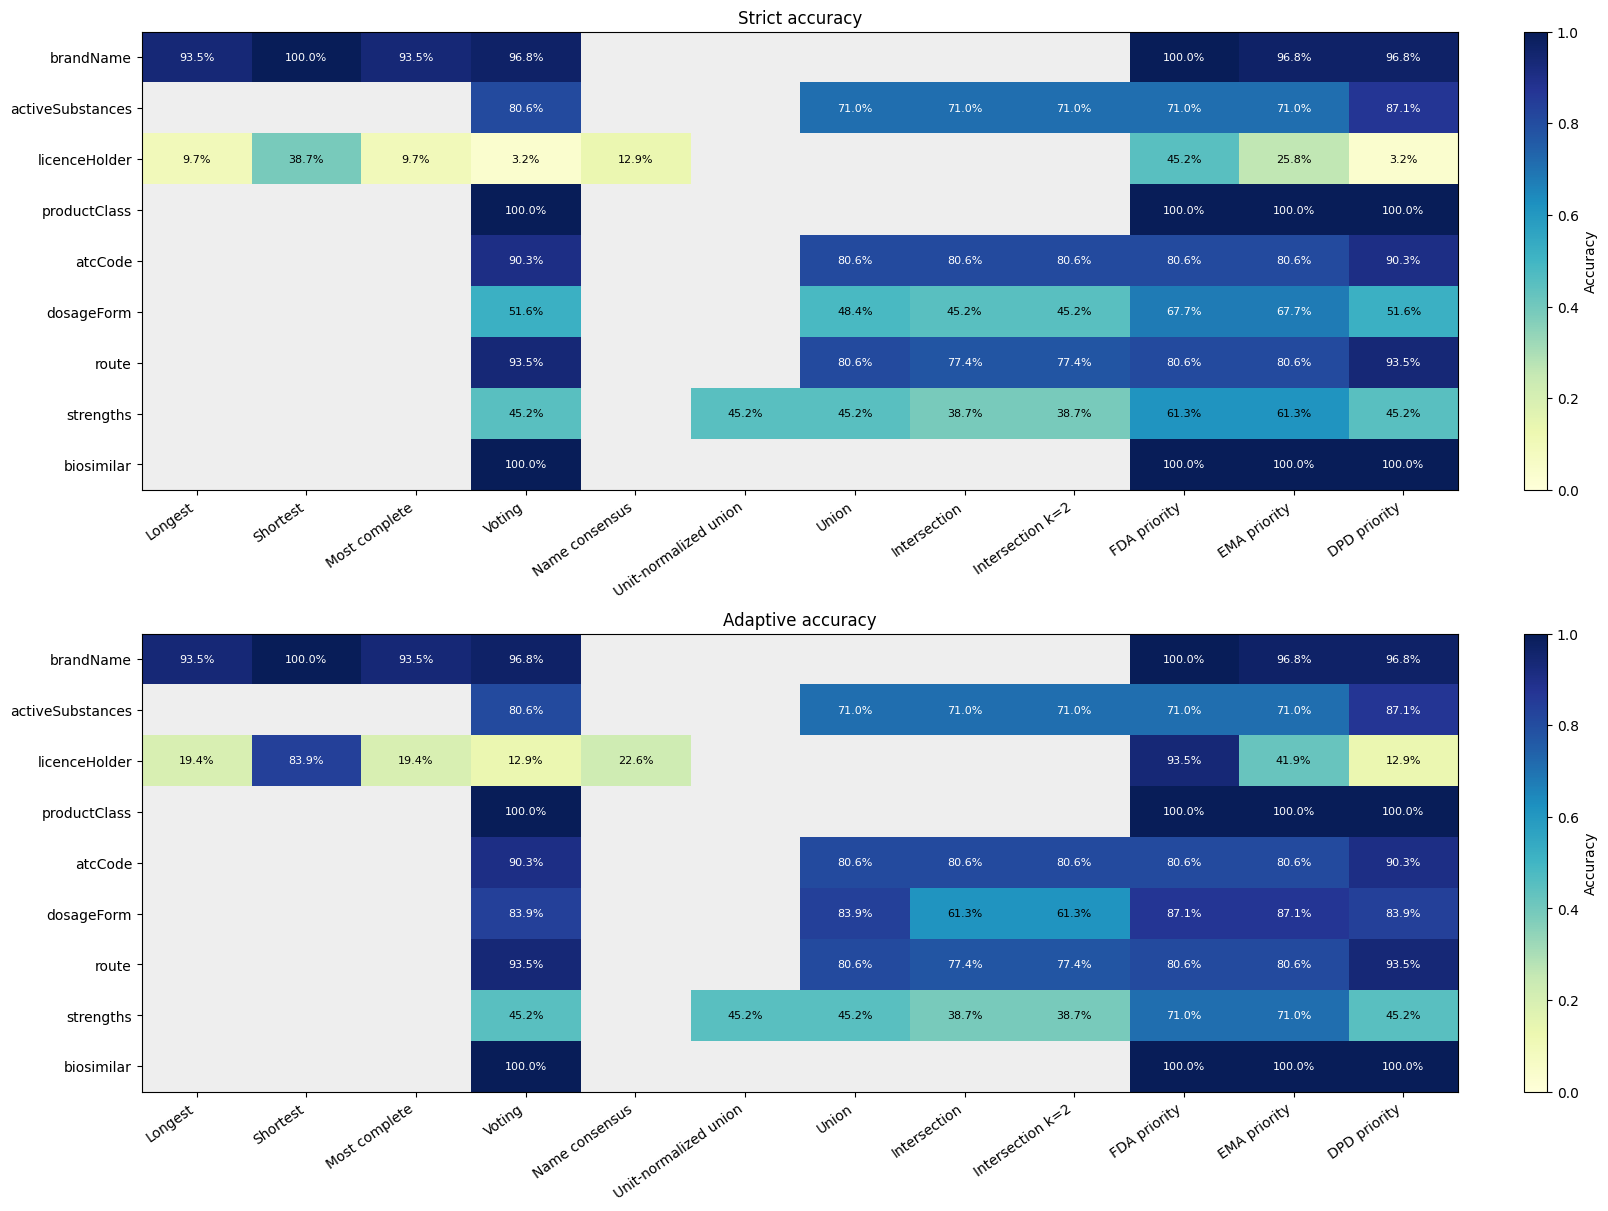

In [231]:
# Compare Strict and Compatible Scores
strict_accuracy = pd.DataFrame({
    attribute: frame['strict_accuracy'] for attribute, frame in attribute_results.items()
}).T.reindex(columns=list(rule_catalog))
accuracy = pd.DataFrame({
    attribute: frame['accuracy'] for attribute, frame in attribute_results.items()
}).T.reindex(columns=list(rule_catalog))
result_summary = pd.DataFrame({
    'simple_strict': {attribute: simple_metrics['strict_' + attribute + '_accuracy'] for attribute in fusion_attributes},
    'best_strict': strict_accuracy.max(axis=1),
    'best_adaptive': accuracy.max(axis=1),
})
display(result_summary.round(4))
display(count_accuracy.round(4))

# Plot Attribute Accuracies
fig, axes = plt.subplots(2, 1, figsize=(16, 12), layout='constrained')
cmap = plt.get_cmap('YlGnBu').copy()
cmap.set_bad('#eeeeee')
for ax, (title, table) in zip(axes, [('Strict accuracy', strict_accuracy), ('Adaptive accuracy', accuracy)]):
    image = ax.imshow(np.ma.masked_invalid(table.to_numpy()), cmap=cmap, vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(table.columns)), table.columns, rotation=35, ha='right')
    ax.set_yticks(range(len(table)), table.index)
    for i in range(len(table)):
        for j in range(len(table.columns)):
            value = table.iloc[i, j]
            if pd.notna(value):
                ax.text(j, i, f'{value:.1%}', ha='center', va='center',
                        fontsize=8, color='white' if value > 0.65 else 'black')
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label='Accuracy')
fig.savefig(figure_dir / 'attribute_rule_accuracy.png', dpi=200, bbox_inches='tight')
plt.show()

### 6.2 Error summary

Summarize incorrect outputs from each attribute section. Each count covers the two highest adaptive-accuracy levels, including tied rules.

In [221]:
error_summary = pd.DataFrame([
    {'attribute': attribute, 'rule_errors': len(errors),
     'medicines_with_errors': errors['eval_id'].nunique()}
    for attribute, errors in wrong_outputs.items()
]).set_index('attribute')
display(error_summary)

,rule_errors,medicines_with_errors
attribute,,
brandName,3,2
activeSubstances,10,6
licenceHolder,7,5
productClass,0,0
atcCode,36,6
dosageForm,23,6
route,22,7
strengths,86,19
biosimilar,0,0


### 6.3 Best rules and ties

- Select the highest adaptive accuracy.
- Break ties using the highest strict accuracy.
- If still tied, keep the simple rule when it is among the tied rules.
- Leave remaining ties unresolved and print the tied rules and outputs.

In [222]:
best_rows = []
selected_rules = {}
tie_rows = []
for attribute, scores in attribute_results.items():
    # Rank Accuracy
    best = scores.loc[scores['accuracy'] == scores['accuracy'].max()]
    finalists = best.loc[best['strict_accuracy'] == best['strict_accuracy'].max()]
    for label, row in best.iterrows():
        best_rows.append({
            'attribute': attribute, 'rule': label, 'accuracy': row['accuracy'],
            'strict_accuracy': row['strict_accuracy'], 'tied': len(best) > 1,
        })

    # Resolve Ties
    simple = simple_rules[attribute]
    if len(finalists) == 1:
        selected_rules[attribute] = finalists.index[0]
    elif simple in finalists.index:
        selected_rules[attribute] = simple
    else:
        for label, row in finalists.iterrows():
            tie_rows.append({
                'attribute': attribute, 'rule': label,
                'accuracy': row['accuracy'], 'strict_accuracy': row['strict_accuracy'],
            })

best_rules = pd.DataFrame(best_rows)
ties = pd.DataFrame(tie_rows, columns=['attribute', 'rule', 'accuracy', 'strict_accuracy'])
display(best_rules.rename(columns={'accuracy': 'adaptive_accuracy'}))
print('Unresolved ties:')
display(ties.rename(columns={'accuracy': 'adaptive_accuracy'}))
for attribute in ties['attribute'].unique():
    display(tied_outputs[attribute].loc[
        tied_outputs[attribute]['rule'].isin(ties.loc[ties['attribute'] == attribute, 'rule'])
    ])

,attribute,rule,adaptive_accuracy,strict_accuracy,tied
0,brandName,Shortest,1.000000,1.000000,True
1,brandName,FDA priority,1.000000,1.000000,True
2,activeSubstances,DPD priority,0.870968,0.870968,False
3,licenceHolder,FDA priority,0.935484,0.451613,False
4,productClass,Voting,1.000000,1.000000,True
5,productClass,FDA priority,1.000000,1.000000,True
6,productClass,EMA priority,1.000000,1.000000,True
7,productClass,DPD priority,1.000000,1.000000,True
8,atcCode,Voting,0.903226,0.903226,True
9,atcCode,DPD priority,0.903226,0.903226,True


Unresolved ties:


,attribute,rule,adaptive_accuracy,strict_accuracy
0,brandName,Shortest,1.000000,1.000000
1,brandName,FDA priority,1.000000,1.000000
2,atcCode,Voting,0.903226,0.903226
3,atcCode,DPD priority,0.903226,0.903226
4,dosageForm,FDA priority,0.870968,0.677419
5,dosageForm,EMA priority,0.870968,0.677419
6,route,Voting,0.935484,0.935484
7,route,DPD priority,0.935484,0.935484
8,strengths,FDA priority,0.709677,0.612903
9,strengths,EMA priority,0.709677,0.612903


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,brandName,Shortest,FDA_AGENERASE|AMPRENAVIR,"{'DPD': ['agenerase'], 'EMA': ['agenerase'], '...",agenerase,agenerase
1,brandName,Shortest,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': ['bosulif'], 'EMA': ['bosulif'], 'FDA'...",bosulif,bosulif
2,brandName,Shortest,FDA_CINQAIR|RESLIZUMAB,"{'DPD': ['cinqair'], 'EMA': ['cinqaero'], 'FDA...",cinqair,cinqair
3,brandName,Shortest,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': ['elelyso'], 'EMA': ['elelyso'], 'FDA'...",elelyso,elelyso
4,brandName,Shortest,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': ['hemlibra'], 'EMA': ['hemlibra'], 'FD...",hemlibra,hemlibra
...,...,...,...,...,...,...
57,brandName,FDA priority,FDA_IONSYS|FENTANYL HYDROCHLORIDE,"{'DPD': [], 'EMA': ['ionsys'], 'FDA': ['ionsys']}",ionsys,ionsys
58,brandName,FDA priority,FDA_MIPLYFFA|ARIMOCLOMOL CITRATE,"{'DPD': [], 'EMA': ['miplyffa'], 'FDA': ['mipl...",miplyffa,miplyffa
59,brandName,FDA priority,FDA_MYCAPSSA|OCTREOTIDE ACETATE,"{'DPD': [], 'EMA': ['mycapssa'], 'FDA': ['myca...",mycapssa,mycapssa
60,brandName,FDA priority,FDA_VIJOICE|ALPELISIB,"{'DPD': [], 'EMA': ['vijoice'], 'FDA': ['vijoi...",vijoice,vijoice


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,atcCode,Voting,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [['j05ae05']], 'EMA': [['j05ae05']], '...","(j05ae05,)",[j05ae05]
1,atcCode,Voting,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [['l01ea04']], 'EMA': [['l01ea04']], '...","(l01ea04,)",[l01ea04]
2,atcCode,Voting,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [['r03dx08']], 'EMA': [['r03dx08']], '...","(r03dx08,)",[r03dx08]
3,atcCode,Voting,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [['a16ab11']], 'EMA': [['a16ab11']], '...","(a16ab11,)",[a16ab11]
4,atcCode,Voting,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [['b02bx06']], 'EMA': [['b02bx06']], '...","(b02bx06,)",[b02bx06]
...,...,...,...,...,...,...
57,atcCode,DPD priority,FDA_IONSYS|FENTANYL HYDROCHLORIDE,"{'DPD': [], 'EMA': [['n02ab03']], 'FDA': [None]}",[n02ab03],[n02ab03]
58,atcCode,DPD priority,FDA_MIPLYFFA|ARIMOCLOMOL CITRATE,"{'DPD': [], 'EMA': [['n07']], 'FDA': [None]}",[n07],[n07xx17]
59,atcCode,DPD priority,FDA_MYCAPSSA|OCTREOTIDE ACETATE,"{'DPD': [], 'EMA': [['h01cb02']], 'FDA': [None]}",[h01cb02],[h01cb02]
60,atcCode,DPD priority,FDA_VIJOICE|ALPELISIB,"{'DPD': [], 'EMA': [['l01em03']], 'FDA': [None]}",[l01em03],[l01em03]


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,dosageForm,FDA priority,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [['capsule', 'liquid']], 'EMA': [None]...","[capsule, solution]","[capsule, solution]"
1,dosageForm,FDA priority,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [['tablet']], 'EMA': [None], 'FDA': [[...","[capsule, tablet]","[capsule, tablet]"
2,dosageForm,FDA priority,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [['solution']], 'EMA': [None], 'FDA': ...",[injection],[injection]
3,dosageForm,FDA priority,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [['powder for solution']], 'EMA': [Non...",[powder],[powder for solution]
4,dosageForm,FDA priority,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [['solution']], 'EMA': [None], 'FDA': ...",[injection],[injection]
...,...,...,...,...,...,...
57,dosageForm,EMA priority,FDA_IONSYS|FENTANYL HYDROCHLORIDE,"{'DPD': [], 'EMA': [None], 'FDA': [['transderm...",[transdermal patch],[transdermal patch]
58,dosageForm,EMA priority,FDA_MIPLYFFA|ARIMOCLOMOL CITRATE,"{'DPD': [], 'EMA': [None], 'FDA': [['capsule']]}",[capsule],[capsule]
59,dosageForm,EMA priority,FDA_MYCAPSSA|OCTREOTIDE ACETATE,"{'DPD': [], 'EMA': [None], 'FDA': [['capsule, ...","[capsule, delayed-release]","[capsule, delayed-release]"
60,dosageForm,EMA priority,FDA_VIJOICE|ALPELISIB,"{'DPD': [], 'EMA': [None], 'FDA': [None]}",None,"[granules, tablet]"


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,route,Voting,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [['oral']], 'EMA': [None], 'FDA': [['o...","(oral,)",[oral]
1,route,Voting,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [['oral']], 'EMA': [None], 'FDA': [['o...","(oral,)",[oral]
2,route,Voting,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [['intravenous']], 'EMA': [None], 'FDA...","(intravenous,)",[intravenous]
3,route,Voting,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [['intravenous']], 'EMA': [None], 'FDA...","(intravenous,)",[intravenous]
4,route,Voting,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [['subcutaneous']], 'EMA': [None], 'FD...","(subcutaneous,)",[subcutaneous]
...,...,...,...,...,...,...
57,route,DPD priority,FDA_IONSYS|FENTANYL HYDROCHLORIDE,"{'DPD': [], 'EMA': [None], 'FDA': [['iontophor...","[iontophoresis, transdermal]","[iontophoresis, transdermal]"
58,route,DPD priority,FDA_MIPLYFFA|ARIMOCLOMOL CITRATE,"{'DPD': [], 'EMA': [None], 'FDA': [['oral']]}",[oral],[oral]
59,route,DPD priority,FDA_MYCAPSSA|OCTREOTIDE ACETATE,"{'DPD': [], 'EMA': [None], 'FDA': [['oral']]}",[oral],[oral]
60,route,DPD priority,FDA_VIJOICE|ALPELISIB,"{'DPD': [], 'EMA': [None], 'FDA': [['oral']]}",[oral],[oral]


,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value
0,strengths,FDA priority,FDA_AGENERASE|AMPRENAVIR,"{'DPD': [[('50', 'mg'), ('150', 'mg'), ('15', ...","[(150, mg), (15, mg/mL), (50, mg)]","[(50, mg), (150, mg), (15, mg/mL)]"
1,strengths,FDA priority,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,"{'DPD': [[('100', 'mg'), ('500', 'mg'), ('400'...","[(100, mg), (400, mg), (500, mg), (50, mg)]","[(50, mg), (100, mg), (400, mg), (500, mg)]"
2,strengths,FDA priority,FDA_CINQAIR|RESLIZUMAB,"{'DPD': [[('10', 'mg')]], 'EMA': [None], 'FDA'...","[(10, mg/mL)]","[(10, mg/mL)]"
3,strengths,FDA priority,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [[('200', 'U')]], 'EMA': [None], 'FDA'...","[(200, U/vial)]","[(200, U)]"
4,strengths,FDA priority,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [[('30', 'mg'), ('60', 'mg'), ('105', ...","[(150, mg/mL), (150, mg), (30, mg/mL), (150, m...","[(30, mg/mL), (150, mg/mL)]"
...,...,...,...,...,...,...
57,strengths,EMA priority,FDA_IONSYS|FENTANYL HYDROCHLORIDE,"{'DPD': [], 'EMA': [None], 'FDA': [[('40', 'mc...","[(40, mcg/actuation)]","[(40, mcg/actuation)]"
58,strengths,EMA priority,FDA_MIPLYFFA|ARIMOCLOMOL CITRATE,"{'DPD': [], 'EMA': [None], 'FDA': [[('124', 'm...","[(124, mg), (47, mg), (62, mg), (93, mg)]","[(47, mg), (62, mg), (93, mg), (124, mg)]"
59,strengths,EMA priority,FDA_MYCAPSSA|OCTREOTIDE ACETATE,"{'DPD': [], 'EMA': [None], 'FDA': [[('20', 'mg...","[(20, mg)]","[(20, mg)]"
60,strengths,EMA priority,FDA_VIJOICE|ALPELISIB,"{'DPD': [], 'EMA': [None], 'FDA': [[('125', 'm...","[(125, mg), (200, mg), (50, mg), (50, mg/packet)]","[(50, mg), (125, mg), (200, mg)]"


#### Manual tie-breaker selections

Apply these choices after the score-based tie checks.

| Attribute | Selected rule |
|---|---|
| `brandName` | FDA priority |
| `atcCode` | Voting |
| `dosageForm` | FDA priority |
| `route` | Voting |
| `strengths` | FDA priority |

In [223]:
# Apply Manual Tie-Breakers
manual_tie_breakers = {
    'brandName': 'FDA priority',
    'atcCode': 'Voting',
    'dosageForm': 'FDA priority',
    'route': 'Voting',
    'strengths': 'FDA priority',
}
selected_rules.update(manual_tie_breakers)
display(pd.Series(selected_rules, name='selected_rule').rename_axis('attribute').to_frame())

,selected_rule
attribute,
activeSubstances,DPD priority
licenceHolder,FDA priority
productClass,Voting
biosimilar,Voting
brandName,FDA priority
atcCode,Voting
dosageForm,FDA priority
route,Voting
strengths,FDA priority


### 6.4 Input consistency

$G_a$ is the number of multi-source groups with a value for attribute $a$.

$$
C_a = \frac{\text{groups with agreeing values for attribute }a}{G_a}
$$

,consistency
attribute,
brandName,0.9355
activeSubstances,0.8387
activeSubstanceCount,1.0000
licenceHolder,0.0000
productClass,1.0000
atcCode,0.9032
dosageForm,0.6667
route,0.8065
strengths,0.5806


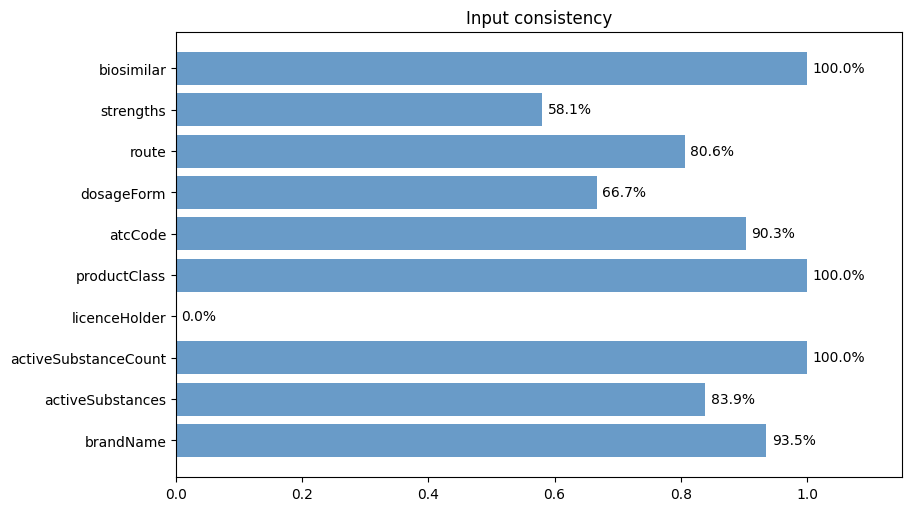

In [232]:
# Input Consistency
groups = build_record_groups_from_correspondences(list(datasets.values()), correspondences, id_column='id')
consistency_rows = []
for attribute in attributes:
    agreements = []
    for group in groups:
        values = [record[attribute] for record in group.records if _is_valid_value(record[attribute])]
        if len(group.records) > 1 and values:
            agreements.append(all(comparison_rules[attribute](values[0], value) for value in values[1:]))
    consistency_rows.append({'attribute': attribute, 'consistency': pd.Series(agreements, dtype=float).mean()})
consistency = pd.DataFrame(consistency_rows).set_index('attribute')

display(consistency.round(4))

# Plot Input Consistency
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
bars = ax.barh(consistency.index, consistency['consistency'], color='#699bc8')
ax.bar_label(bars, labels=[f'{value:.1%}' for value in consistency['consistency']], padding=4)
ax.set_xlim(0, 1.15)
ax.set_title('Input consistency')
fig.savefig(figure_dir / 'input_consistency.png', dpi=200, bbox_inches='tight')
plt.show()

### 6.5 Combined configuration

Run the selected rules together and derive `activeSubstanceCount` from the fused `activeSubstances`. Compare strict accuracy, adaptive accuracy, density and input consistency against the simple configuration.

In [225]:
# Run Selected Rules
final_fused = None
final_metrics = None
configurations = [('Simple rules', simple_fused, simple_metrics)]
if len(selected_rules) == len(fusion_attributes):
    final_fused, final_metrics = run_fusion(selected_rules)
    configurations.append(('Selected rules', final_fused, final_metrics))
else:
    print('Combined configuration pending unresolved ties:', ', '.join(ties['attribute'].unique()))

# Compare Configurations
combined_metrics = pd.DataFrame([
    {
        'configuration': name,
        'strict_accuracy': metrics['strict_overall_accuracy'],
        'adaptive_accuracy': metrics['overall_accuracy'],
        'density': frame[attributes].map(_is_valid_value).to_numpy().mean(),
        'input_consistency': consistency['consistency'].mean(),
    }
    for name, frame, metrics in configurations
]).set_index('configuration')
display(combined_metrics.round(4))

,strict_accuracy,adaptive_accuracy,density,input_consistency
configuration,,,,
Simple rules,0.7129,0.7581,0.9968,0.7731
Selected rules,0.8452,0.9226,0.9968,0.7731


### 6.6 Density

$N$ is the number of records in each source or fused dataset and $A=10$.

- **Attribute density:**

$$
D_a = \frac{\text{populated values for attribute }a}{N}
$$

- **Overall density:**

$$
D = \frac{\text{populated attribute cells}}{N \times A}
$$

,DPD,EMA,FDA,Simple rules,Selected rules
brandName,1.0,1.0,1.0000,1.0000,1.0000
activeSubstances,1.0,1.0,1.0000,1.0000,1.0000
activeSubstanceCount,1.0,1.0,1.0000,1.0000,1.0000
licenceHolder,1.0,1.0,1.0000,1.0000,1.0000
productClass,1.0,1.0,1.0000,1.0000,1.0000
atcCode,1.0,1.0,0.0000,1.0000,1.0000
dosageForm,1.0,0.0,0.9130,0.9677,0.9677
route,1.0,0.0,0.9565,1.0000,1.0000
strengths,1.0,0.0,1.0000,1.0000,1.0000
biosimilar,1.0,1.0,0.0000,1.0000,1.0000


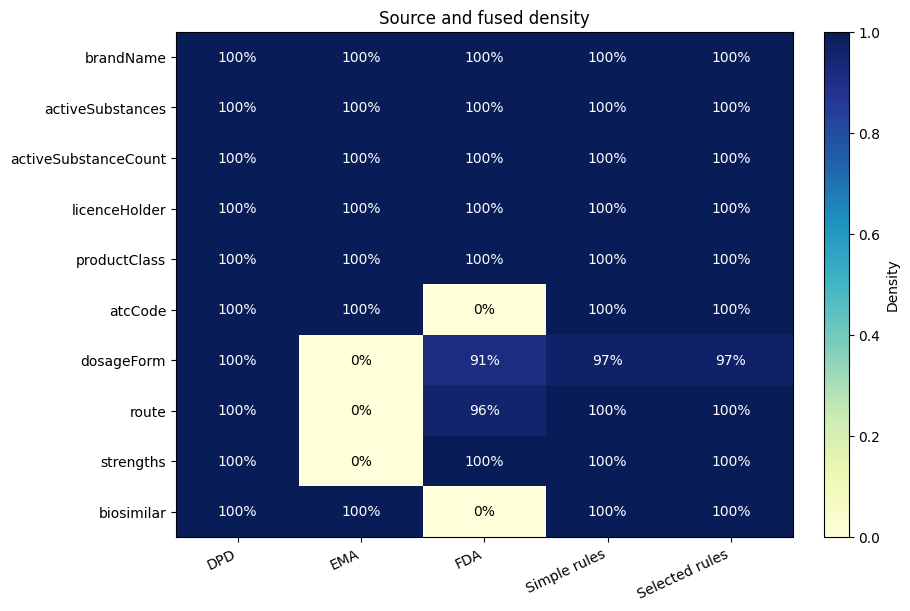

In [233]:
# Plot Density
density_frames = {**datasets, 'Simple rules': simple_fused}
if final_fused is not None:
    density_frames['Selected rules'] = final_fused
density = pd.DataFrame({name: frame[attributes].map(_is_valid_value).mean()
                        for name, frame in density_frames.items()})
display(density.round(4))

fig, ax = plt.subplots(figsize=(9, 6), layout='constrained')
image = ax.imshow(density, vmin=0, vmax=1, cmap='YlGnBu', aspect='auto')
ax.set_xticks(range(len(density.columns)), density.columns, rotation=25, ha='right')
ax.set_yticks(range(len(attributes)), attributes)
for i in range(len(attributes)):
    for j in range(len(density.columns)):
        value = density.iloc[i, j]
        ax.text(j, i, f'{value:.0%}', ha='center', va='center',
                color='white' if value > 0.65 else 'black')
fig.colorbar(image, ax=ax, label='Density')
ax.set_title('Source and fused density')
fig.savefig(figure_dir / 'fusion_density.png', dpi=200, bbox_inches='tight')
plt.show()

### 6.7 Selected rules and final metrics

Selected rule for every attribute, with the combined configuration's scores. `activeSubstanceCount` is derived from `activeSubstances`.

,selected_rule,selection,strict_accuracy,adaptive_accuracy,density,equally_best_rules
attribute,,,,,,
brandName,FDA priority,Manual tie-breaker,1.0000,1.0000,1.0000,"Shortest, FDA priority"
activeSubstances,DPD priority,Score-based,0.8710,0.8710,1.0000,DPD priority
activeSubstanceCount,Count fused activeSubstances,Derived,1.0000,1.0000,1.0000,
licenceHolder,FDA priority,Score-based,0.4516,0.9355,1.0000,FDA priority
productClass,Voting,Score-based,1.0000,1.0000,1.0000,"Voting, FDA priority, EMA priority, DPD priority"
atcCode,Voting,Manual tie-breaker,0.9032,0.9032,1.0000,"Voting, DPD priority"
dosageForm,FDA priority,Manual tie-breaker,0.6774,0.8710,0.9677,"FDA priority, EMA priority"
route,Voting,Manual tie-breaker,0.9355,0.9355,1.0000,"Voting, DPD priority"
strengths,FDA priority,Manual tie-breaker,0.6129,0.7097,1.0000,"FDA priority, EMA priority"


,strict_accuracy,adaptive_accuracy,density,input_consistency
configuration,,,,
Simple rules,0.7129,0.7581,0.9968,0.7731
Selected rules,0.8452,0.9226,0.9968,0.7731


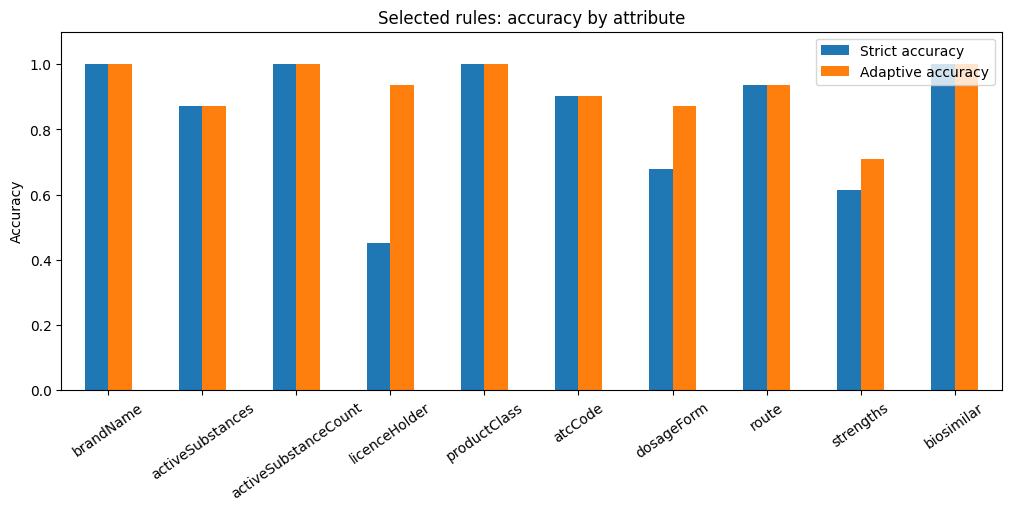

In [234]:
# Summarize Selected Rules
selected_rows = []
for attribute in fusion_attributes:
    label = selected_rules[attribute]
    alternatives = best_rules.loc[best_rules['attribute'] == attribute, 'rule']
    selected_rows.append({
        'attribute': attribute, 'selected_rule': label,
        'selection': 'Manual tie-breaker' if attribute in manual_tie_breakers else 'Score-based',
        'strict_accuracy': final_metrics['strict_' + attribute + '_accuracy'],
        'adaptive_accuracy': final_metrics[attribute + '_accuracy'],
        'density': final_fused[attribute].map(_is_valid_value).mean(),
        'equally_best_rules': ', '.join(alternatives),
    })
selected_rows.append({
    'attribute': 'activeSubstanceCount', 'selected_rule': 'Count fused activeSubstances',
    'selection': 'Derived',
    'strict_accuracy': final_metrics['strict_activeSubstanceCount_accuracy'],
    'adaptive_accuracy': final_metrics['activeSubstanceCount_accuracy'],
    'density': final_fused['activeSubstanceCount'].map(_is_valid_value).mean(),
    'equally_best_rules': '',
})
selected_rule_table = pd.DataFrame(selected_rows).set_index('attribute').reindex(attributes)
display(selected_rule_table.round(4))
display(combined_metrics.round(4))

# Plot Final Accuracy
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
selected_rule_table[['strict_accuracy', 'adaptive_accuracy']].plot.bar(ax=ax, ylim=(0, 1.1))
ax.set_ylabel('Accuracy')
ax.set_xlabel('')
ax.set_title('Selected rules: accuracy by attribute')
ax.tick_params(axis='x', rotation=35)
ax.legend(['Strict accuracy', 'Adaptive accuracy'])
fig.savefig(figure_dir / 'selected_rule_accuracy.png', dpi=200, bbox_inches='tight')
plt.show()

### 6.8 Remaining errors

Show the selected configuration’s strict and adaptive mismatches with `fusion_inputs`, `fused_value` and `gold_value`.

In [228]:
# Show Remaining Errors
expected = gold.set_index('id')
selected_errors = []
for row in final_fused.to_dict('records'):
    for attribute in attributes:
        actual = row[attribute]
        target = expected.at[row['eval_id'], attribute]
        compared = (actual, row['_eval_routes']) if attribute == 'dosageForm' else actual
        strict_correct = comparison_rules[attribute](actual, target)
        adaptive_correct = domain_comparisons[attribute](compared, target)
        if not strict_correct or not adaptive_correct:
            selected_errors.append({
                'attribute': attribute, 'rule': selected_rule_table.at[attribute, 'selected_rule'],
                'eval_id': row['eval_id'],
                'fusion_inputs': {
                    source: frame.loc[frame['id'].isin(row['_fusion_sources']), attribute].tolist()
                    for source, frame in datasets.items()
                },
                'fused_value': actual, 'gold_value': target,
                'strict_correct': strict_correct, 'adaptive_correct': adaptive_correct,
            })
selected_errors = pd.DataFrame(selected_errors)
display(selected_errors)

,attribute,rule,eval_id,fusion_inputs,fused_value,gold_value,strict_correct,adaptive_correct
0,licenceHolder,FDA priority,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': ['pfizer canada ulc'], 'EMA': ['pfizer...",pfizer,pfizer inc.,False,True
1,dosageForm,FDA priority,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [['powder for solution']], 'EMA': [Non...",[powder],[powder for solution],False,True
2,strengths,FDA priority,FDA_ELELYSO|TALIGLUCERASE ALFA,"{'DPD': [[('200', 'U')]], 'EMA': [None], 'FDA'...","[(200, U/vial)]","[(200, U)]",False,False
3,strengths,FDA priority,FDA_HEMLIBRA|EMICIZUMAB,"{'DPD': [[('30', 'mg'), ('60', 'mg'), ('105', ...","[(150, mg/mL), (150, mg), (30, mg/mL), (150, m...","[(30, mg/mL), (150, mg/mL)]",False,False
4,licenceHolder,FDA priority,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': ['merck canada inc'], 'EMA': ['merck s...",msd sub merck,merck sharp & dohme llc,False,False
5,dosageForm,FDA priority,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': [['powder for solution']], 'EMA': [Non...",[injection],[powder for solution],False,False
6,strengths,FDA priority,FDA_INVANZ|ERTAPENEM SODIUM,"{'DPD': [[('1', 'g')]], 'EMA': [None], 'FDA': ...","[(1, g/vial)]","[(1, g)]",False,False
7,licenceHolder,FDA priority,FDA_KANUMA|SEBELIPASE ALFA,"{'DPD': ['alexion pharma gmbh'], 'EMA': ['alex...",alexion pharm,"alexion pharmaceuticals, inc.",False,True
8,licenceHolder,FDA priority,FDA_KESIMPTA|OFATUMUMAB,{'DPD': ['novartis pharmaceuticals canada inc'...,novartis,novartis pharmaceuticals corporation,False,True
9,dosageForm,FDA priority,FDA_KESIMPTA|OFATUMUMAB,"{'DPD': [['solution']], 'EMA': [None], 'FDA': ...",[solution],[injection],False,True


## 7. Observations and conclusions

| Attribute | Best strict accuracy | Best adaptive accuracy | Best adaptive rule |
|---|---:|---:|---|
| `licenceHolder` | 45.2% | 93.5% | FDA priority |
| `dosageForm` | 67.7% | 87.1% | FDA priority |
| `strengths` | 61.3% | 71.0% | FDA priority |

- Adaptive scores recognize `licenceHolder` resemblance, broad `dosageForm` compatibility and equivalent/rounded `strengths`. These increases describe changes in evaluation.
- Dataset-priority rules achieve the highest adaptive accuracy for `licenceHolder`, `dosageForm` and `strengths` on this sample.
- Remaining errors include missing source values, amount-versus-concentration differences and product/jurisdiction scope differences.
- Manual tie-breakers select FDA priority for `brandName`, `dosageForm` and `strengths`, and voting for `atcCode` and `route`.
- The combined configuration achieves **84.52% strict accuracy**, **92.26% adaptive accuracy** and **99.68% density**. The simple baseline achieves 71.29%, 75.81% and 99.68%, respectively. Input consistency is 77.31% for both configurations.
- Scores describe development performance on the same sample used for rule selection.

## 8. Save results

Save metrics, errors, tied outputs and fused samples in `csv/`. Save figures in `figures/`.

The experiment findings are recorded in [report.md](report.md).

In [235]:
# Save Tables
strict_accuracy.to_csv(csv_dir / 'strict_attribute_accuracy.csv')
result_summary.to_csv(csv_dir / 'result_summary.csv')
accuracy.to_csv(csv_dir / 'attribute_rule_accuracy.csv')
count_accuracy.to_csv(csv_dir / 'derived_count_accuracy.csv')
best_rules.rename(columns={'accuracy': 'adaptive_accuracy'}).to_csv(csv_dir / 'best_rules.csv', index=False)
ties.rename(columns={'accuracy': 'adaptive_accuracy'}).to_csv(csv_dir / 'tied_rules.csv', index=False)
pd.concat(tied_outputs.values(), ignore_index=True).to_csv(csv_dir / 'tied_rule_values.csv', index=False)
pd.concat([*wrong_outputs.values(), count_errors], ignore_index=True).to_csv(csv_dir / 'incorrect_outputs.csv', index=False)
pd.concat(attribute_results, names=['attribute', 'rule']).rename(columns={'accuracy': 'adaptive_accuracy'}).to_csv(csv_dir / 'attribute_metrics.csv')
combined_metrics.to_csv(csv_dir / 'combined_metrics.csv')
density.to_csv(csv_dir / 'fusion_density.csv')
consistency.to_csv(csv_dir / 'input_consistency.csv')
selected_rule_table.to_csv(csv_dir / 'selected_rules.csv')
selected_errors.to_csv(csv_dir / 'selected_rule_errors.csv', index=False)
if final_fused is not None:
    final_fused[['eval_id', *attributes]].to_csv(csv_dir / 'selected_fused_sample.csv', index=False)
print(f'Outputs: {work_dir}')

Outputs: C:\Users\LENOVO\Documents\Personal\Study\Master\Mannheim University\HWS 2026\IE 670 Web Data Integration\wdi-drug-integration\notebooks\data_fusion_rule_experiment
